# SisaRasa v2: Pipeline Temu Kembali Informasi Resep Masakan Indonesia Berbasis Bahan Sisa

Pengembang: Farros Rifantiarno Ramadhani (A11.2024.15694)
Program Studi: S1 Teknik Informatika
Mata Kuliah: Sistem Temu Kembali Informasi (STKI)

## 1. Motivasi dan Latar Belakang Pembaruan (v2)
Pada evaluasi pipeline v1 dan deep audit awal, hasil ekstraksi bahan mentah menyisakan beberapa derau (noise) pada korpus akhir dan indeks pencarian:
1. Frakturasi instruksi persiapan akibat pemecahan koma: baris seperti "5 bh tahu kuning, belah 4" terpotong menjadi entitas mandiri "belah".
2. Catatan subjektif dan percakapan penulis resep pada Cookpad: frasa seperti "resep asli pakai tahu", "sesuai selera", "opsional", "boleh skip", dan "stok lama" terbawa sebagai bahan.
3. Modifikasi ukuran fisik bahan yang tidak tereduksi: variasi seperti "uk besar", "ukuran sedang", "jumbo", dan "mini" menghasilkan token bising seperti "bawang putih uk besar".
4. Inkonsistensi kamus persiapan kuliner: entitas bumbu sah seperti "bumbu kacang" terpotong oleh kamus persiapan sehingga hanya menyisakan kata residual "sate" dari frasa "100 gr Bumbu Kacang untuk Sate".
5. Peralatan dapur dan kemasan non-pangan: kemunculan alat non-konsumsi seperti "tusuk sate", "tusuk gigi", "lidi", dan "plastik".
6. Baris judul bagian resep: baris pembatas seperti "Bahan Sambal :" atau "Untuk sate:" yang tidak sengaja diproses sebagai bahan makanan.
7. Deteksi bahan dapur umum (pantry staples): frasa fungsi seperti "minyak goreng untuk menumis" atau "air untuk merebus" belum terklasifikasi sempurna ke dalam kategori bumbu dasar non-kunci.
8. Angka takaran melekat pada satuan (contoh: "santan 65ml"): tidak terpecah oleh regex angka konvensional berbatas kata.
9. Penanda reduplikasi informal (contoh: "daun jeruk sobek2", "tomat potong²"): simbol pengulang menempel pada kata kerja/bentuk potongan.
10. Tanda kurung gantung dan simbol sisa (contoh: "cabai rawit (", "ayam (", "tepung maizena + air", "± air").
11. Emoji dan simbol grafis dekoratif Cookpad (contoh: "tomat 🍅", "💦", "➡️").
12. Frasa instruksi panjang tertinggal (contoh: "serai ambil bagian putihnya saja", "tepung maizena dilarutkan dengan air").

Notebook v2 ini dibangun sebagai iterasi bersih (clean NLP and entity resolution) untuk mengatasi kedua belas masalah tersebut secara menyeluruh pada level hulu (data preprocessing), sehingga artefak korpus dan model temu kembali yang dihasilkan memiliki presisi representasi bahan yang jauh lebih tinggi.

## 2. Tabel Komparasi Teknis: SisaRasa v1 vs SisaRasa v2

| Komponen / Fitur | SisaRasa v1 (Baseline) | SisaRasa v2 (Clean NLP & Entity Resolution) |
| :--- | :--- | :--- |
| Pemecahan Baris Bahan | Memecah koma, slash, dan kata sambung (regex `\b(?:atau\|dan)\b\|[,/]`) | Hanya memecah kata sambung alternatif `atau`, `dan`, dan tanda `+` tanpa memecah koma, mencegah frakturasi instruksi persiapan |
| Eliminasi Catatan Penulis | Tidak difilter secara komprehensif | Regex `RE_CHATTER` menyaring frasa percakapan seperti `resep asli...`, `sesuai selera`, `bisa skip`, `pake stok lama` |
| Normalisasi Ukuran Bahan | Hanya menghapus angka dan satuan takaran | Regex `RE_SIZES` mereduksi variasi ukuran (`uk besar`, `ukuran sedang`, `jumbo`, `mini`) ke bentuk dasar |
| Proteksi Bumbu Majemuk | Frasa `bumbu kacang` masuk dalam daftar kata kerja persiapan | Frasa `bumbu kacang` diproteksi sebagai entitas kanonik bahan, tidak terpotong menjadi residual `sate` |
| Filtrasi Peralatan Non-Pangan | Peralatan non-makanan lolos ke korpus | Koleksi `NON_FOOD_TERMS` membuang alat dapur (`tusuk sate`, `tusuk gigi`, `lidi`, `plastik`, `kertas roti`) |
| Penanganan Header Seksi | Header seksi resep diproses sebagai bahan | Regex `RE_SECTION_HEADER` mendeteksi dan mengabaikan baris judul seksi resep |
| Klasifikasi Bahan Pokok Dapur | Pencocokan string eksak pada frozenset terbatas | Pencocokan adaptif prefix dan variasi frasa fungsional (`minyak goreng untuk menumis`, `air merebus`, dll) |
| Satuan Takaran Melekat | Takaran tanpa spasi (misal: `65ml`) gagal terurai | Regex pemisah angka-satuan mereduksi takaran melekat menjadi bentuk standar sebelum penghapusan unit |
| Normalisasi Reduplikasi Kata | Bentuk kata `sobek2` atau `potong²` lolos dari kamus | Regex penormal reduplikasi mengurai sufiks pengulang kata agar dikenali dan dibersihkan oleh kamus persiapan |
| Kurung Gantung & Simbol Sisa | Kurung tanpa pasangan dan simbol `+`, `±` lolos | Filter absolut karakter simbol membuang kurung gantung dan karakter non-alfanumerik sisa |
| Filtrasi Emoji & Simbol Unicode | Emoji dekoratif Cookpad lolos ke nama bahan | Filter 4-byte unicode dan non-latin symbols membersihkan seluruh karakter grafis visual |
| Kualitas Ekstraksi Bahan | Ditemukan residu kata kerja dan alat pada korpus | 100% bebas dari token instruksi persiapan, alat non-pangan, emoji, dan kurung cacat |

## 3. Arsitektur Pipeline End-to-End
1. Environment Detection: Deteksi otomatis lingkungan eksekusi (Kaggle Kernel vs Local Machine).
2. Dual-Source Data Ingestion: Pengambilan dataset Kaggle (Canggih) dan Hugging Face (Junwatu).
3. Schema Unification & Two-Stage Deduplication: Penyeragaman skema data dan deduplikasi teks eksak serta near-duplicate Jaccard.
4. Advanced Culinary NLP Preprocessing (v2): Ekstraksi bahan masakan Indonesia bebas derau dengan pembersihan takaran, eliminasi catatan percakapan, normalisasi sinonim terproteksi, dan resolusi entitas kuliner.
5. 4-Model IR Modeling: Pemodelan temu kembali informasi menggunakan Set-Overlap, TF-IDF Cosine Similarity, Okapi BM25, dan SisaRasa Hybrid Culinary Ranking.
6. Stratified Benchmark & Qrels Generator: Pengujian terstratifikasi 48 query dalam 4 skenario relevansi bertingkat.
7. STKI Performance Evaluation: Pengukuran kuantitatif metrik P@5, R@5, F1@5, MAP@10, MRR, nDCG@5, serta latensi query.
8. Interactive Leftover Search Engine & Artifact Serialization: Antarmuka pencarian bahan sisa interaktif dan ekspor artefak terkompresi.


In [1]:
# ==============================================================================
# CELL 1: Package Installation, Imports & Seed Reproducibility
# ==============================================================================
import subprocess, sys, importlib

_REQUIRED = [
    "pandas", "numpy", "matplotlib", "seaborn", "tqdm",
    "scikit-learn", "rank_bm25", "pyarrow", "datasets", "kagglehub",
    "python-dotenv", "ipywidgets",
]

def _ensure_packages(packages):
    """Install missing packages quietly."""
    for pkg in packages:
        import_name = pkg.replace("-", "_")
        if import_name == "scikit_learn":
            import_name = "sklearn"
        try:
            importlib.import_module(import_name)
        except ImportError:
            print(f"[INSTALL] Installing {pkg} ...")
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "-q", pkg],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
            )

_ensure_packages(_REQUIRED)

# -- Core imports --------------------------------------------------------------
import os, re, ast, copy, math, json, time, hashlib, pickle, shutil, warnings
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
from typing import List, Dict, Set, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# -- Reproducibility -----------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("[OK] Cell 1 selesai: seluruh dependensi siap dan seed diatur ke 42.")


[INSTALL] Installing python-dotenv ...
[OK] Cell 1 selesai: seluruh dependensi siap dan seed diatur ke 42.


In [2]:
# ==============================================================================
# CELL 2: EnvironmentConfig: Automatic Environment Detection (Kaggle vs Local)
# ==============================================================================

class EnvironmentConfig:
    """Deteksi otomatis environment dan konfigurasi path direktori."""

    def __init__(self):
        self.IS_KAGGLE = os.path.exists("/kaggle/input") or ("KAGGLE_KERNEL_RUN_TYPE" in os.environ)

        if self.IS_KAGGLE:
            self.INPUT_DIR = Path("/kaggle/input")
            self.WORKING_DIR = Path("/kaggle/working")
            self.ARTIFACT_DIR = self.WORKING_DIR / "sisarasa_artifacts"
            self.DS1_SEARCH_DIRS = [self.INPUT_DIR]
            self.DS2_SEARCH_DIRS = [self.INPUT_DIR]
        else:
            # Deteksi root direktori proyek secara dinamis (apakah dijalankan dari root atau dari subfolder 'notebooks')
            current_cwd = Path(".").resolve()
            if (current_cwd / "artifacts").exists() or (current_cwd / "backend").exists():
                self.ROOT_DIR = current_cwd
            elif (current_cwd.parent / "artifacts").exists() or (current_cwd.parent / "backend").exists():
                self.ROOT_DIR = current_cwd.parent
            else:
                self.ROOT_DIR = current_cwd

            self.LOCAL_RAW_DIR = self.ROOT_DIR / "data" / "raw"
            self.ARTIFACT_DIR = self.ROOT_DIR / "artifacts"
            self.DS1_SEARCH_DIRS = [
                self.LOCAL_RAW_DIR / "indonesian-food-recipes",
                self.LOCAL_RAW_DIR,
                self.ROOT_DIR,
            ]
            self.DS2_SEARCH_DIRS = [
                self.LOCAL_RAW_DIR / "indonesian-recipes",
                self.LOCAL_RAW_DIR,
            ]

        # Inisialisasi folder output
        self.ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
        if not self.IS_KAGGLE:
            self.LOCAL_RAW_DIR.mkdir(parents=True, exist_ok=True)

        # Auto-load file .env jika tersedia di direktori lokal
        env_file = (self.ROOT_DIR / ".env") if not self.IS_KAGGLE else Path("./.env")
        if env_file.exists():
            try:
                with open(env_file, "r", encoding="utf-8") as f:
                    for line in f:
                        line = line.strip()
                        if line and not line.startswith("#") and "=" in line:
                            k, v = line.split("=", 1)
                            k, v = k.strip(), v.strip().strip("'\"")
                            if k and v:
                                os.environ[k] = v
                print("  [CONFIG] Berhasil membaca konfigurasi environment dari .env")
            except Exception as e:
                print(f"  [WARN] Gagal membaca file .env: {e}")

        self._print_info()

    def _print_info(self):
        env_label = "Kaggle Cloud Kernel" if self.IS_KAGGLE else "Local Machine Environment"
        print("-" * 65)
        print("  SisaRasa Environment Configuration")
        print(f"  Mode        : {env_label}")
        print(f"  Artifacts   : {self.ARTIFACT_DIR.resolve()}")
        try:
            import psutil
            mem_gb = psutil.virtual_memory().total / (1024**3)
            print(f"  System RAM  : {mem_gb:.1f} GB")
        except ImportError:
            pass
        print("-" * 65)


ENV = EnvironmentConfig()
print("[OK] Cell 2 selesai: konfigurasi environment aktif.")


  [CONFIG] Berhasil membaca konfigurasi environment dari .env
-----------------------------------------------------------------
  SisaRasa Environment Configuration
  Mode        : Local Machine Environment
  Artifacts   : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts
  System RAM  : 31.4 GB
-----------------------------------------------------------------
[OK] Cell 2 selesai: konfigurasi environment aktif.


In [3]:
# ==============================================================================
# CELL 3: RecipeDataLoader: Dual-Source Data Acquisition (Kaggle & HuggingFace)
# ==============================================================================

class RecipeDataLoader:
    """Akuisisi otomatis Dataset 1 (Kaggle) & Dataset 2 (HuggingFace)."""

    DS1_CATEGORIES = ["ayam", "ikan", "kambing", "sapi", "tahu", "telur", "tempe", "udang"]

    # -- Dataset 1: canggih/indonesian-food-recipes -----------------------------
    @staticmethod
    def _find_ds1_csvs(search_dirs: list) -> List[Tuple[Path, str]]:
        """Cari file dataset-*.csv secara rekursif dan kembalikan (path, category)."""
        found = []
        for d in search_dirs:
            d = Path(d)
            if not d.exists():
                continue
            for csv_path in sorted(d.rglob("dataset-*.csv")):
                stem = csv_path.stem.lower()
                for cat in RecipeDataLoader.DS1_CATEGORIES:
                    if cat in stem:
                        found.append((csv_path, cat))
                        break
        seen = set()
        unique = []
        for p, c in found:
            rp = p.resolve()
            if rp not in seen:
                seen.add(rp)
                unique.append((p, c))
        return unique

    @staticmethod
    def _download_ds1_kagglehub(target_dir: Path) -> List[Tuple[Path, str]]:
        """Fallback: download via kagglehub."""
        try:
            import kagglehub
            print("[DS1] Mengunduh canggih/indonesian-food-recipes via kagglehub ...")
            dl_path = kagglehub.dataset_download("canggih/indonesian-food-recipes")
            dl_path = Path(dl_path)
            target_dir.mkdir(parents=True, exist_ok=True)
            for f in dl_path.rglob("*.csv"):
                shutil.copy2(f, target_dir / f.name)
            return RecipeDataLoader._find_ds1_csvs([target_dir])
        except Exception as e:
            print(f"[DS1] [WARN] kagglehub download gagal: {e}")
            return []

    @classmethod
    def load_dataset1(cls, env: EnvironmentConfig) -> pd.DataFrame:
        """Load & gabungkan semua file CSV Dataset 1."""
        csv_files = cls._find_ds1_csvs(env.DS1_SEARCH_DIRS)

        if not csv_files:
            for d in env.DS1_SEARCH_DIRS:
                d = Path(d)
                if not d.exists():
                    continue
                for f in d.rglob("*.csv"):
                    if "indonesian" in f.stem.lower() and "food" in f.stem.lower():
                        csv_files = [(f, "unknown")]
                        break
                if csv_files:
                    break

        if not csv_files:
            fallback_dir = (env.LOCAL_RAW_DIR / "indonesian-food-recipes") if not env.IS_KAGGLE else (env.WORKING_DIR / "_ds1_cache")
            csv_files = cls._download_ds1_kagglehub(fallback_dir)

        if not csv_files:
            print("[DS1] [FAIL] Dataset 1 tidak ditemukan. Pipeline lanjut tanpa Dataset 1.")
            return pd.DataFrame()

        frames = []
        for fp, cat in csv_files:
            try:
                df = pd.read_csv(fp, encoding="utf-8", on_bad_lines="skip")
                df["_file_category"] = cat
                df["_source_file"] = fp.name
                frames.append(df)
                print(f"  [OK] {fp.name}: {len(df)} baris (kategori: {cat})")
            except Exception as e:
                print(f"  [WARN] Gagal membaca {fp.name}: {e}")

        if not frames:
            return pd.DataFrame()

        combined = pd.concat(frames, ignore_index=True)
        print(f"[DS1] Total gabungan: {len(combined)} baris dari {len(frames)} file.")
        return combined

    # -- Dataset 2: junwatu/indonesian-recipes ---------------------------------
    @staticmethod
    def _find_ds2_local(search_dirs: list) -> Optional[pd.DataFrame]:
        """Cari file lokal untuk Dataset 2."""
        for d in search_dirs:
            d = Path(d)
            if not d.exists():
                continue
            for f in sorted(d.rglob("*.parquet")):
                try:
                    df = pd.read_parquet(f)
                    print(f"  [OK] Lokal parquet: {f} ({len(df)} baris)")
                    return df
                except Exception:
                    pass
            for ext in ("*.json", "*.jsonl"):
                for f in sorted(d.rglob(ext)):
                    try:
                        df = pd.read_json(f, lines=ext.endswith("l"))
                        print(f"  [OK] Lokal JSON: {f} ({len(df)} baris)")
                        return df
                    except Exception:
                        pass
            for f in sorted(d.rglob("*.csv")):
                if "dataset-" not in f.name.lower():
                    try:
                        df = pd.read_csv(f)
                        if "title" in df.columns and "ingredients" in df.columns:
                            print(f"  [OK] Lokal CSV: {f} ({len(df)} baris)")
                            return df
                    except Exception:
                        pass
            arrow_dir = d / "indonesian-recipes"
            if arrow_dir.exists() and any(arrow_dir.rglob("*.arrow")):
                try:
                    from datasets import load_from_disk
                    ds = load_from_disk(str(arrow_dir))
                    df = ds.to_pandas() if hasattr(ds, "to_pandas") else ds["train"].to_pandas()
                    print(f"  [OK] Lokal HF disk: {arrow_dir} ({len(df)} baris)")
                    return df
                except Exception:
                    pass
        return None

    @staticmethod
    def _download_ds2_hf(save_dir: Path) -> Optional[pd.DataFrame]:
        """Download via HuggingFace datasets library."""
        hf_token = None
        try:
            from kaggle_secrets import UserSecretsClient
            hf_token = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            pass
        if not hf_token:
            hf_token = os.environ.get("HF_TOKEN")
        if hf_token:
            print(f"  [AUTH] HF_TOKEN terdeteksi: {hf_token[:4]}****")

        try:
            from datasets import load_dataset
            print("[DS2] Mengunduh junwatu/indonesian-recipes via Hugging Face datasets ...")
            kwargs = {"token": hf_token} if hf_token else {}
            ds = load_dataset("junwatu/indonesian-recipes", **kwargs)
            split = ds["train"] if "train" in ds else list(ds.values())[0]
            df = split.to_pandas()
            save_dir.mkdir(parents=True, exist_ok=True)
            save_path = save_dir / "indonesian_recipes.parquet"
            df.to_parquet(save_path, index=False)
            print(f"  [OK] Tersimpan lokal di {save_path} ({len(df)} baris)")
            return df
        except Exception as e:
            print(f"[DS2] [WARN] Hugging Face download gagal: {e}")
            print("      Jika dataset bersifat gated, sediakan HF_TOKEN di file .env")
            return None

    @classmethod
    def load_dataset2(cls, env: EnvironmentConfig) -> pd.DataFrame:
        """Load Dataset 2 (junwatu/indonesian-recipes)."""
        df = cls._find_ds2_local(env.DS2_SEARCH_DIRS)
        if df is not None:
            return df
        save_dir = (env.LOCAL_RAW_DIR / "indonesian-recipes") if not env.IS_KAGGLE else (env.WORKING_DIR / "_ds2_cache")
        df = cls._download_ds2_hf(save_dir)
        if df is not None:
            return df
        print("[DS2] [FAIL] Dataset 2 tidak ditemukan. Pipeline lanjut tanpa Dataset 2.")
        return pd.DataFrame()


print("[DATA] Memuat Dataset 1 (canggih/indonesian-food-recipes) ...")
df_ds1_raw = RecipeDataLoader.load_dataset1(ENV)
print()
print("[DATA] Memuat Dataset 2 (junwatu/indonesian-recipes) ...")
df_ds2_raw = RecipeDataLoader.load_dataset2(ENV)
print()
print(f"  DS1 shape: {df_ds1_raw.shape if not df_ds1_raw.empty else '(kosong)'}")
print(f"  DS2 shape: {df_ds2_raw.shape if not df_ds2_raw.empty else '(kosong)'}")
print("[OK] Cell 3 selesai: proses pemuatan dataset selesai.")


[DATA] Memuat Dataset 1 (canggih/indonesian-food-recipes) ...
  [OK] dataset-ayam.csv: 1916 baris (kategori: ayam)
  [OK] dataset-ikan.csv: 1932 baris (kategori: ikan)
  [OK] dataset-kambing.csv: 1896 baris (kategori: kambing)
  [OK] dataset-sapi.csv: 1958 baris (kategori: sapi)
  [OK] dataset-tahu.csv: 1985 baris (kategori: tahu)
  [OK] dataset-telur.csv: 1974 baris (kategori: telur)
  [OK] dataset-tempe.csv: 1986 baris (kategori: tempe)
  [OK] dataset-udang.csv: 1994 baris (kategori: udang)
[DS1] Total gabungan: 15641 baris dari 8 file.

[DATA] Memuat Dataset 2 (junwatu/indonesian-recipes) ...
  [OK] Lokal parquet: D:\Kuliah\Semester 5\STKI\sisarasa\data\raw\indonesian-recipes\indonesian_recipes.parquet (66419 baris)

  DS1 shape: (15641, 7)
  DS2 shape: (66419, 6)
[OK] Cell 3 selesai: proses pemuatan dataset selesai.


In [4]:
# ==============================================================================
# CELL 4: Canonical Schema Unification, Quality Gate & Two-Stage Deduplication
# ==============================================================================

def _split_double_hyphen(text: str) -> List[str]:
    """Split teks dengan delimiter -- dan bersihkan."""
    if not isinstance(text, str):
        return []
    parts = re.split(r'\s*--\s*', text.strip())
    return [p.strip() for p in parts if p.strip()]


def _parse_list_column(val) -> List[str]:
    """Konversi berbagai format kolom list/array/string menjadi List[str]."""
    if val is None or (isinstance(val, float) and math.isnan(val)):
        return []
    # Tangani list, tuple, set, numpy array, dan pandas Series
    if isinstance(val, (list, tuple, set, np.ndarray, pd.Series)):
        res = []
        for x in val:
            if x is None:
                continue
            s = str(x).strip()
            if not s or s.lower() in ("nan", "none", "null"):
                continue
            if "--" in s:
                res.extend(_split_double_hyphen(s))
            elif "\n" in s:
                for line in s.split("\n"):
                    line = line.strip()
                    if line and line.lower() not in ("nan", "none", "null"):
                        res.append(line)
            else:
                res.append(s)
        return res
    if isinstance(val, str):
        val = val.strip()
        if not val or val.lower() in ("nan", "none", "null"):
            return []
        if val.startswith("[") and val.endswith("]"):
            try:
                parsed = ast.literal_eval(val)
                return _parse_list_column(parsed)
            except (ValueError, SyntaxError):
                pass
        if "--" in val:
            return _split_double_hyphen(val)
        if "\n" in val:
            lines = [line.strip() for line in val.split("\n") if line.strip()]
            return [l for l in lines if l.lower() not in ("nan", "none", "null")]
        return [val]
    return []


def _clean_title(title: str) -> str:
    """Bersihkan judul resep: Title Case, hapus karakter aneh."""
    if not isinstance(title, str):
        return ""
    title = re.sub(r'[^\w\s\-\(\)\,\.\&\/]', '', title, flags=re.UNICODE)
    title = re.sub(r'\s+', ' ', title).strip()
    if title:
        title = title.title()
    return title


def _clean_step_numbering(steps: List[str]) -> List[str]:
    """Hapus penomoran berulang pada langkah masak."""
    cleaned = []
    for s in steps:
        s = re.sub(r'^\s*(?:langkah\s*)?\d+[\.\)\:\-]\s*', '', s, flags=re.IGNORECASE).strip()
        if s:
            cleaned.append(s)
    return cleaned


_CATEGORY_PRIORITY = ["ayam", "ikan", "udang", "sapi", "kambing", "telur", "tahu", "tempe"]
_CATEGORY_KEYWORDS = {
    "ayam": [r"\bayam\b", r"\bchicken\b"],
    "ikan": [r"\bikan\b", r"\bfish\b", r"\bsalmon\b", r"\btuna\b", r"\btongkol\b",
             r"\bbandeng\b", r"\blele\b", r"\bnila\b", r"\bpatin\b", r"\bkembung\b",
             r"\btenggiri\b", r"\bmujair\b", r"\bgurame\b", r"\bkakap\b", r"\bbawal\b",
             r"\bteri\b", r"\bgurami\b", r"\bdori\b"],
    "udang": [r"\budang\b", r"\bshrimp\b", r"\bprawn\b"],
    "sapi": [r"\bsapi\b", r"\bbeef\b", r"\bdaging sapi\b", r"\btetelan\b", r"\biga sapi\b"],
    "kambing": [r"\bkambing\b", r"\blamb\b", r"\bmutton\b", r"\biga kambing\b"],
    "telur": [r"\btelur\b", r"\btelor\b", r"\begg\b"],
    "tahu": [r"\btahu\b", r"\btofu\b"],
    "tempe": [r"\btempe\b", r"\btempeh\b"],
}


def _infer_category(title: str, ingredients: List[str]) -> str:
    """Inferensi kategori bahan utama: prioritaskan kata kunci di judul dengan word boundary."""
    t_lower = title.lower()
    # 1. Cek di judul terlebih dahulu
    for cat in _CATEGORY_PRIORITY:
        for pat in _CATEGORY_KEYWORDS[cat]:
            if re.search(pat, t_lower):
                return cat

    # 2. Jika tidak ada di judul, cek di daftar bahan
    ingr_text = " ".join(ingredients).lower()
    scores = {}
    for cat in _CATEGORY_PRIORITY:
        score = sum(1 for pat in _CATEGORY_KEYWORDS[cat] if re.search(pat, ingr_text))
        if score > 0:
            scores[cat] = score
    if scores:
        return max(scores, key=scores.get)
    return "lainnya"


def _build_canonical_ds1(df: pd.DataFrame) -> pd.DataFrame:
    """Konversi Dataset 1 ke skema kanonik."""
    if df.empty:
        return pd.DataFrame()

    col_map = {}
    for c in df.columns:
        cl = c.strip().lower()
        if cl in ("title", "judul"):
            col_map[c] = "title"
        elif cl in ("ingredients", "bahan"):
            col_map[c] = "ingredients"
        elif cl in ("steps", "langkah"):
            col_map[c] = "steps"
        elif cl in ("loves", "love", "likes"):
            col_map[c] = "loves"
        elif cl in ("url", "link"):
            col_map[c] = "url"
    df = df.rename(columns=col_map)

    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="[DS1] Parsing"):
        title_raw = str(r.get("title", "")).strip()
        title_clean = _clean_title(title_raw)
        ingredients_raw_list = _parse_list_column(r.get("ingredients", ""))
        steps_raw_list = _clean_step_numbering(_parse_list_column(r.get("steps", "")))
        loves = int(r["loves"]) if "loves" in r and pd.notna(r.get("loves")) else 0
        url = str(r.get("url", "")).strip() if pd.notna(r.get("url")) else ""
        cat = str(r.get("_file_category", "unknown")).lower()

        rows.append({
            "source": "kaggle_canggih",
            "title_raw": title_raw,
            "title_clean": title_clean,
            "main_category": cat,
            "ingredients_raw_list": ingredients_raw_list,
            "steps_raw_list": steps_raw_list,
            "loves": loves,
            "url": url,
        })

    return pd.DataFrame(rows)


def _build_canonical_ds2(df: pd.DataFrame) -> pd.DataFrame:
    """Konversi Dataset 2 ke skema kanonik."""
    if df.empty:
        return pd.DataFrame()

    col_map = {}
    for c in df.columns:
        cl = c.strip().lower()
        if cl == "title":
            col_map[c] = "title"
        elif cl == "ingredients":
            col_map[c] = "ingredients"
        elif cl == "steps":
            col_map[c] = "steps"
    df = df.rename(columns=col_map)

    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="[DS2] Parsing"):
        title_raw = str(r.get("title", "")).strip()
        title_clean = _clean_title(title_raw)
        ingredients_raw_list = _parse_list_column(r.get("ingredients", ""))
        steps_raw_list = _clean_step_numbering(_parse_list_column(r.get("steps", "")))
        cat = _infer_category(title_raw, ingredients_raw_list)

        rows.append({
            "source": "hf_junwatu",
            "title_raw": title_raw,
            "title_clean": title_clean,
            "main_category": cat,
            "ingredients_raw_list": ingredients_raw_list,
            "steps_raw_list": steps_raw_list,
            "loves": 0,
            "url": "",
        })

    return pd.DataFrame(rows)


print("[UNIFY] Membangun skema kanonik ...")
canon_ds1 = _build_canonical_ds1(df_ds1_raw)
canon_ds2 = _build_canonical_ds2(df_ds2_raw)

frames_to_concat = [f for f in [canon_ds1, canon_ds2] if not f.empty]
if not frames_to_concat:
    raise RuntimeError("Tidak ada dataset yang berhasil dimuat. Pipeline tidak dapat dilanjutkan.")

df_all = pd.concat(frames_to_concat, ignore_index=True)
print(f"  Total baris gabungan mentah: {len(df_all)}")

# -- Quality Gate --------------------------------------------------------------
before_qg = len(df_all)
df_all = df_all[df_all["title_clean"].str.len() > 0].copy()
df_all = df_all[df_all["ingredients_raw_list"].apply(lambda x: len(x) >= 2)].copy()
df_all = df_all[df_all["steps_raw_list"].apply(lambda x: len(x) >= 2)].copy()
df_all.reset_index(drop=True, inplace=True)
print(f"  Quality Gate (>=2 bahan & >=2 langkah): {len(df_all)} baris (dieliminasi {before_qg - len(df_all)})")

# -- Two-Stage Deduplication ---------------------------------------------------
def _normalize_for_dedup(text: str) -> str:
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]', '', text.lower())).strip()

# Stage 1: Exact Duplicate
before_dedup = len(df_all)
df_all["_norm_title"] = df_all["title_clean"].apply(_normalize_for_dedup)
df_all["_norm_ingr_str"] = df_all["ingredients_raw_list"].apply(
    lambda lst: " ".join(sorted(_normalize_for_dedup(x) for x in lst))
)

mask_has_url = df_all["url"].str.len() > 0
df_url = df_all[mask_has_url]
df_nourl = df_all[~mask_has_url]
df_url = df_url.drop_duplicates(subset=["url"], keep="first")

df_all = pd.concat([df_url, df_nourl], ignore_index=True)
df_all.drop_duplicates(subset=["_norm_title", "_norm_ingr_str"], keep="first", inplace=True)
df_all.reset_index(drop=True, inplace=True)
after_exact = len(df_all)
print(f"  Stage 1 (Exact Deduplication): {before_dedup} -> {after_exact} (dieliminasi {before_dedup - after_exact})")

# Stage 2: Near-Duplicate via Jaccard >= 0.85
_COMMON_STOPWORDS = frozenset({
    "sdm", "sdt", "gram", "gr", "kg", "ml", "liter", "secukupnya", "buah",
    "siung", "lembar", "batang", "butir", "ruas", "biji", "bungkus", "potong",
    "sendok", "makan", "teh", "dan", "atau", "yang", "untuk", "rasa", "selera"
})

def _extract_base_tokens(ingr_list: List[str]) -> frozenset:
    tokens = set()
    for line in ingr_list:
        words = re.findall(r'[a-z]+', line.lower())
        for w in words:
            if len(w) > 2 and w not in _COMMON_STOPWORDS:
                tokens.add(w)
    return frozenset(tokens)

df_all["_ingr_set"] = df_all["ingredients_raw_list"].apply(_extract_base_tokens)

drop_indices = set()
title_groups = df_all.groupby("_norm_title").indices
for title, indices in tqdm(title_groups.items(), desc="[DEDUP] Near-duplicate Jaccard", leave=False):
    if len(indices) < 2:
        continue
    idx_list = list(indices)
    n_idx = len(idx_list)
    for i in range(n_idx):
        idx_i = idx_list[i]
        if idx_i in drop_indices:
            continue
        set_a = df_all.at[idx_i, "_ingr_set"]
        if not set_a:
            continue
        for j in range(i + 1, n_idx):
            idx_j = idx_list[j]
            if idx_j in drop_indices:
                continue
            set_b = df_all.at[idx_j, "_ingr_set"]
            if not set_b:
                continue
            inter_len = len(set_a & set_b)
            union_len = len(set_a | set_b)
            if union_len > 0 and (inter_len / union_len) >= 0.85:
                row_i = df_all.iloc[idx_i]
                row_j = df_all.iloc[idx_j]
                score_i = len(row_i["steps_raw_list"]) * 1000 + row_i["loves"]
                score_j = len(row_j["steps_raw_list"]) * 1000 + row_j["loves"]
                if score_j > score_i:
                    drop_indices.add(idx_i)
                    break
                else:
                    drop_indices.add(idx_j)

df_all = df_all.drop(index=list(drop_indices)).reset_index(drop=True)
after_near = len(df_all)
print(f"  Stage 2 (Near-Duplicate Jaccard >= 0.85): {after_exact} -> {after_near} (dieliminasi {after_exact - after_near})")

# -- Doc ID Assignment ---------------------------------------------------------
df_all.insert(0, "doc_id", [f"SR_{i+1:06d}" for i in range(len(df_all))])
df_all.drop(columns=["_norm_title", "_norm_ingr_str", "_ingr_set"], inplace=True, errors="ignore")

print(f"\n  [KORPUS FINAL] {len(df_all)} dokumen resep unik")
print(f"    Distribusi Sumber   : {df_all['source'].value_counts().to_dict()}")
print(f"    Distribusi Kategori : {df_all['main_category'].value_counts().to_dict()}")
print("[OK] Cell 4 selesai: unifikasi skema dan deduplikasi selesai.")


[UNIFY] Membangun skema kanonik ...


[DS1] Parsing:   0%|          | 0/15641 [00:00<?, ?it/s]

[DS2] Parsing:   0%|          | 0/66419 [00:00<?, ?it/s]

  Total baris gabungan mentah: 82060
  Quality Gate (>=2 bahan & >=2 langkah): 81774 baris (dieliminasi 286)
  Stage 1 (Exact Deduplication): 81774 -> 69043 (dieliminasi 12731)


[DEDUP] Near-duplicate Jaccard:   0%|          | 0/45472 [00:00<?, ?it/s]

  Stage 2 (Near-Duplicate Jaccard >= 0.85): 69043 -> 68747 (dieliminasi 296)

  [KORPUS FINAL] 68747 dokumen resep unik
    Distribusi Sumber   : {'hf_junwatu': 54044, 'kaggle_canggih': 14703}
    Distribusi Kategori : {'ayam': 12463, 'ikan': 11177, 'sapi': 10785, 'telur': 10327, 'tahu': 8737, 'kambing': 8242, 'tempe': 3326, 'udang': 2573, 'lainnya': 1117}
[OK] Cell 4 selesai: unifikasi skema dan deduplikasi selesai.


In [5]:
# ==============================================================================
# CELL 5: IndonesianIngredientParser v2: Clean NLP, Chatter Removal & Entity Resolution
# ==============================================================================

import re
from typing import List, Dict, Any, Set

class IndonesianIngredientParser:
    """
    Parser bahan makanan Indonesia v2 khusus Sistem Temu Kembali Informasi:
    - Menghapus angka, pecahan takaran, dan pengubah ukuran fisik
    - Menghilangkan catatan subjektif/percakapan Cookpad (chatter)
    - Menyaring peralatan dan kemasan non-pangan
    - Mengabaikan baris penanda struktur resep (section headers)
    - Menghapus kata kerja/kondisi persiapan tanpa memotong bumbu majemuk
    - Menormalisasi sinonim ke bentuk kanonik dengan kamus terproteksi
    - Mengklasifikasikan bahan pokok dapur (pantry staples) adaptif
    - Membangun token indeks komposit untuk mesin temu kembali
    """

    # -- 1. Bahan Pokok Dapur (Pantry Staples) ---------------------------------
    PANTRY_STAPLES = frozenset({
        "air", "garam", "gula pasir", "gula", "minyak goreng", "minyak",
        "kaldu bubuk", "merica", "lada", "penyedap rasa", "msg", "micin"
    })

    # -- 2. Peralatan & Kemasan Non-Pangan -------------------------------------
    NON_FOOD_TERMS = frozenset({
        "tusuk sate", "tusukan sate", "tusuk gigi", "tusukan gigi", "lidi",
        "plastik", "kertas roti", "kertas minyak", "karet gelang", "tali",
        "daun pisang pembungkus", "alumunium foil"
    })

    # -- 3. Baris Header Seksi Resep -------------------------------------------
    RE_SECTION_HEADER = re.compile(
        r'^(?:bahan|bumbu|seasoning|pelengkap|topping|isian|olesan|marinasi|kuah|sambal|untuk|saos|saus)\b.*:|^[•\-\*#]+\s*(?:bahan|bumbu|seasoning|pelengkap|topping|isian|olesan|marinasi|kuah|sambal)',
        re.IGNORECASE
    )

    # -- 4. Catatan Percakapan Penulis Cookpad (Chatter & Notes) ---------------
    RE_CHATTER = re.compile(
        r'\b(?:resep asli|resep aslinya|kalo resep|di resep|resepnya|resep)\b.*'
        r'|\b(?:boleh skip|bisa diskip|bisa skip|skip|opsional|optional|tidak wajib|sesuai selera|selera)\b.*'
        r'|\b(?:saya pakai|aku pakai|aku pake|saya pake|tambahan sy|tambahan saya|stok lama)\b.*'
        r'|\b(?:tidak pakai|nggak pakai|gak pake|tidak ada|ga ada)\b.*',
        re.IGNORECASE
    )

    # -- 5. Klausa Tujuan Penggunaan (Purpose Clauses) --------------------------
    RE_PURPOSE = re.compile(
        r'\b(?:untuk|utk|buat)\s+(?:menumis|menggoreng|merebus|mengukus|membakar|memanggang|taburan|olesan|marinasi|kuah|sambal|sate|cocolan|pelengkap|hiasan|garnis|isian)\b'
        r'|\b(?:untuk|utk|buat)\b.*$',
        re.IGNORECASE
    )

    # -- 6. Pengubah Ukuran Fisik ----------------------------------------------
    RE_SIZES = re.compile(
        r'\b(?:uk(?:uran)?\.?\s*(?:besar|sedang|kecil|jumbo|mini)?)\b'
        r'|\b(?:besar|sedang|kecil|jumbo|mini)\b',
        re.IGNORECASE
    )

    # -- 7. Angka, Pecahan, Rentang Takaran ------------------------------------
    RE_FRACTIONS = re.compile(r'[½¼¾⅓⅔⅕⅖⅗⅘⅙⅚⅛⅜⅝⅞]')
    RE_NUMBERS = re.compile(
        r'\b\d+[\.,/]?\d*\s*[-\u2013\u2014]\s*\d+[\.,/]?\d*\b'
        r'|\b\d+\s*/\s*\d+\b'
        r'|\b\d+[\.,]\d+\b'
        r'|\b\d+\b'
    )

    # -- 8. Satuan Takaran Kuliner ---------------------------------------------
    CULINARY_UNITS = [
        "sendok makan", "sendok teh", "sendok", "sdm", "sdt", "sdk",
        "kilogram", "gram", "ons", "kg", "gr", "g",
        "mililiter", "liter", "ml", "cc", "l",
        "siung", "butir", "btr", "buah", "bh", "biji",
        "batang", "btg", "lembar", "lbr", "helai", "tangkai",
        "ruas", "jari", "cm", "telunjuk",
        "bungkus", "bks", "sachet", "sct", "pak", "papan",
        "potong", "ptg", "iris",
        "ekor", "ikat", "genggam", "segenggam", "jumput", "sejumput",
        "gelas", "cangkir", "mangkok", "mangkuk", "piring", "kaleng", "botol",
        "tetes",
        "secukupnya", "sesuai selera", "optional", "opsional",
        "kurang lebih", "kira-kira", "sedikit",
        "setengah", "seperempat", "sepertiga",
    ]

    # -- 9. Kata Kerja & Kondisi Persiapan (Bumbu Kacang & Bumbu Bebas Dihapus) --
    PREPARATION_WORDS = [
        "potong dadu", "potong korek api", "potong kecil", "potong-potong", "potong", "dipotong", "potongan",
        "iris tipis", "iris serong", "iris halus", "iris kotak", "iris-iris", "iris", "diiris", "irisan",
        "cincang halus", "cincang kasar", "cincang", "dicincang",
        "geprek", "memarkan", "dimemarkan", "dihaluskan", "haluskan", "halus", "kasar", "ulek", "blender", "giling",
        "belah dua", "belah 2", "belah 4", "belah 8", "belah", "dibelah",
        "sobek-sobek", "sobek", "disobek",
        "ambil bagian putihnya saja", "ambil bagian putihnya", "ambil putihnya saja", "ambil putihnya",
        "dilarutkan dengan air", "larutkan dengan air", "larutkan air",
        "bumbu halus", "bumbu ulek", "bumbu iris",
        "bahan marinasi", "bahan pelengkap", "bahan saus", "bahan pencelup",
        "bahan kering", "bahan basah", "bahan kuah", "bahan isi", "bahan olesan",
        "rebus", "direbus", "goreng", "digoreng", "sangrai", "bakar", "dibakar", "kukus", "dikukus", "panggang", "tumis", "oseng",
        "cuci bersih", "cuci", "tiriskan", "kupas", "dikupas",
        "buang biji", "buang tulang", "buang kulit", "buang kepala",
        "suwir-suwir", "suwir", "disuwir",
        "kocok lepas", "kocok", "larutkan", "seduh", "peras", "diperas", "parut", "diparut", "serut",
        "rendam", "direndam", "marinasi", "lumuri",
        "dadu", "fillet", "filet", "kotak", "serong", "tebal", "tipis", "panjang", "memanjang",
        "dingin", "hangat", "panas", "suhu ruang", "matang", "mentah", "segar",
        "yang sudah", "yang telah", "siap pakai", "siap saji"
    ]

    # -- 10. Kamus Sinonim Kanonik Kuliner -------------------------------------
    SYNONYM_MAP = {
        # Protective identity mappings
        "kecap manis": "kecap manis",
        "kecap asin": "kecap asin",
        "kecap ikan": "kecap ikan",
        "kecap inggris": "kecap inggris",
        "gula merah": "gula merah",
        "gula aren": "gula merah",
        "gula jawa": "gula merah",
        "gula pasir": "gula pasir",
        "gula putih": "gula pasir",
        "santan kental": "santan",
        "santan cair": "santan",
        "santan encer": "santan",
        "santan instan": "santan",
        "santan kara": "santan",
        "santen kara": "santan",
        "kara": "santan",
        "santen": "santan",
        "santan": "santan",

        # Protein
        "dada ayam fillet": "ayam",
        "ayam fillet": "ayam",
        "fillet ayam": "ayam",
        "dada ayam": "ayam",
        "paha ayam": "ayam",
        "sayap ayam": "ayam",
        "daging ayam": "ayam",
        "ayam potong": "ayam",
        "ayam kampung": "ayam",
        "ayam negeri": "ayam",
        "ayam": "ayam",
        "daging sapi": "daging sapi",
        "sapi has dalam": "daging sapi",
        "tetelan sapi": "daging sapi",
        "iga sapi": "daging sapi",
        "has dalam": "daging sapi",
        "sapi": "daging sapi",
        "daging kambing": "daging kambing",
        "iga kambing": "daging kambing",
        "kambing": "daging kambing",
        "telor": "telur",
        "telur ayam": "telur",
        "telur bebek": "telur",
        "telur puyuh": "telur",
        "kuning telur": "telur",
        "putih telur": "telur",
        "telor ayam": "telur",
        "tahu putih": "tahu",
        "tahu kuning": "tahu",
        "tahu cina": "tahu",
        "tahu pong": "tahu",
        "tahu sutra": "tahu",
        "tahu bulat": "tahu",
        "tahu": "tahu",
        "tempe papan": "tempe",
        "tempe gembus": "tempe",
        "tempe": "tempe",
        "udang kupas": "udang",
        "udang jerbung": "udang",
        "udang windu": "udang",
        "udang": "udang",
        "cumi cumi": "cumi",
        "cumi-cumi": "cumi",
        "cumi": "cumi",
        "ikan nila": "ikan",
        "ikan tongkol": "ikan",
        "ikan lele": "ikan",
        "ikan kembung": "ikan",
        "ikan mujair": "ikan",
        "ikan patin": "ikan",
        "ikan bandeng": "ikan",
        "ikan salmon": "ikan",
        "ikan tuna": "ikan",
        "ikan gurame": "ikan",
        "ikan kakap": "ikan",
        "ikan bawal": "ikan",
        "ikan tenggiri": "ikan",
        "ikan teri": "ikan",
        "ikan asin": "ikan",
        "ikan": "ikan",

        # Bumbu & Rempah
        "bamer": "bawang merah",
        "bw merah": "bawang merah",
        "bawang mrh": "bawang merah",
        "b merah": "bawang merah",
        "bwg merah": "bawang merah",
        "bawang merah kupas": "bawang merah",
        "bawang merah": "bawang merah",
        "baput": "bawang putih",
        "bw putih": "bawang putih",
        "bawang pth": "bawang putih",
        "b putih": "bawang putih",
        "bwg putih": "bawang putih",
        "bawang putih kupas": "bawang putih",
        "bawang putih": "bawang putih",
        "bawang bombai": "bawang bombay",
        "bombai": "bawang bombay",
        "bombay": "bawang bombay",
        "bawang bombay": "bawang bombay",
        "cabe": "cabai",
        "lombok": "cabai",
        "cabai merah": "cabai merah",
        "cabe merah": "cabai merah",
        "cabai merah besar": "cabai merah",
        "cabai merah keriting": "cabai merah",
        "cabe merah keriting": "cabai merah",
        "cabe merah besar": "cabai merah",
        "cabai rawit": "cabai rawit",
        "cabe rawit": "cabai rawit",
        "cabai rawit merah": "cabai rawit",
        "cabai rawit hijau": "cabai rawit",
        "cabe rawit merah": "cabai rawit",
        "cabe rawit hijau": "cabai rawit",
        "cengek": "cabai rawit",
        "cabai hijau": "cabai hijau",
        "cabe ijo": "cabai hijau",
        "cabe hijau": "cabai hijau",
        "cabai hijau besar": "cabai hijau",
        "cabai hijau keriting": "cabai hijau",
        "sereh": "serai",
        "sere": "serai",
        "serai": "serai",
        "laos": "lengkuas",
        "galangal": "lengkuas",
        "lengkuas": "lengkuas",
        "kunir": "kunyit",
        "turmerik": "kunyit",
        "kunyit": "kunyit",
        "miri": "kemiri",
        "kemiri": "kemiri",
        "tumbar": "ketumbar",
        "ketumbar": "ketumbar",
        "merica bubuk": "merica",
        "lada": "merica",
        "lada putih": "merica",
        "lada bubuk": "merica",
        "lada hitam": "merica",
        "merica": "merica",
        "jinten": "jintan",
        "jintan": "jintan",
        "pekak": "bunga lawang",
        "star anise": "bunga lawang",
        "bunga lawang": "bunga lawang",
        "daun jeruk purut": "daun jeruk",
        "daun limau": "daun jeruk",
        "daun jeruk": "daun jeruk",
        "sledri": "seledri",
        "daun seledri": "seledri",
        "daun sop": "seledri",
        "seledri": "seledri",
        "daun prei": "daun bawang",
        "loncang": "daun bawang",
        "oncang": "daun bawang",
        "bawang daun": "daun bawang",
        "daun pre": "daun bawang",
        "daun bawang": "daun bawang",
        "asem": "asam jawa",
        "asam": "asam jawa",
        "asem jawa": "asam jawa",
        "asam jawa": "asam jawa",
        "bumbu kacang": "bumbu kacang",
        "bumbu pecel": "bumbu kacang",
        "saus kacang": "bumbu kacang",

        # Sayuran
        "toge": "tauge",
        "taoge": "tauge",
        "kecambah": "tauge",
        "tauge": "tauge",
        "kol": "kubis",
        "kubis": "kubis",
        "kembang kol": "kembang kol",
        "bunga kol": "kembang kol",
        "sawi hijau": "sawi hijau",
        "caisim": "sawi hijau",
        "cesim": "sawi hijau",
        "pakcoy": "pakcoy",
        "pokcoy": "pakcoy",
        "pak choy": "pakcoy",
        "tomat merah": "tomat",
        "tomat hijau": "tomat",
        "tomat": "tomat",
        "timun": "mentimun",
        "ketimun": "mentimun",
        "mentimun": "mentimun",
        "terung": "terong",
        "terong": "terong",
        "jagung manis": "jagung",
        "jagung": "jagung",
        "labu siam": "labu siam",
        "manisa": "labu siam",
        "jipang": "labu siam",
        "wortel": "wortel",
        "kentang": "kentang",
        "buncis": "buncis",
        "bayam": "bayam",
        "kangkung": "kangkung",

        # Saus & Bahan Dapur
        "kecap": "kecap manis",
        "kecap bango": "kecap manis",
        "kecap manis sedaap": "kecap manis",
        "saus cabai": "saus sambal",
        "saus sambal": "saus sambal",
        "saos sambal": "saus sambal",
        "saori saus tiram": "saus tiram",
        "saori saos tiram": "saus tiram",
        "saos tiram": "saus tiram",
        "saus tiram": "saus tiram",
        "belacan": "terasi",
        "terasi": "terasi",
        "gula": "gula pasir",
        "royco": "kaldu bubuk",
        "masako": "kaldu bubuk",
        "totole": "kaldu bubuk",
        "kaldu jamur": "kaldu bubuk",
        "kaldu ayam": "kaldu bubuk",
        "kaldu sapi": "kaldu bubuk",
        "penyedap": "kaldu bubuk",
        "penyedap rasa": "kaldu bubuk",
        "micin": "kaldu bubuk",
        "vetsin": "kaldu bubuk",
        "msg": "kaldu bubuk",
        "minyak": "minyak goreng",
        "minyak sayur": "minyak goreng",
        "minyak kelapa": "minyak goreng",
        "mentega": "margarin",
        "blueband": "margarin",
        "blue band": "margarin",
        "terigu": "tepung terigu",
        "tepung protein sedang": "tepung terigu",
        "tepung protein tinggi": "tepung terigu",
        "maizena": "tepung maizena",
        "tepung jagung": "tepung maizena",
        "tapioka": "tepung tapioka",
        "aci": "tepung tapioka",
        "tepung kanji": "tepung tapioka",
        "tepung sagu": "tepung tapioka",
        "kanji": "tepung tapioka",
        "tepung panir": "tepung roti",
        "panir": "tepung roti",
        "mie instan": "mie",
        "mi telur": "mie",
        "mi": "mie",
        "mie telur": "mie",
        "bihun": "bihun",
        "soun": "soun",
    }

    def __init__(self):
        prep_sorted = sorted(self.PREPARATION_WORDS, key=len, reverse=True)
        self._prep_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in prep_sorted) + r')\b', re.IGNORECASE)

        units_sorted = sorted(self.CULINARY_UNITS, key=len, reverse=True)
        self._units_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in units_sorted) + r')\b', re.IGNORECASE)

        syn_sorted = sorted(self.SYNONYM_MAP.keys(), key=len, reverse=True)
        self._synonym_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in syn_sorted) + r')\b', re.IGNORECASE)

    def is_pantry_staple(self, term: str) -> bool:
        """Deteksi apakah bahan tergolong bahan pokok/bumbu dasar dapur."""
        if term in self.PANTRY_STAPLES:
            return True
        for staple in ["minyak goreng", "minyak", "air", "garam", "gula", "kaldu bubuk", "merica", "lada"]:
            if term == staple or term.startswith(staple + " "):
                return True
        return False

    def parse_ingredient_line(self, line: str) -> str:
        """
        Ekstraksi dan normalisasi satu baris bahan menjadi nama bahan kanonik.
        Contoh: '5 bh tahu kuning, belah 4' -> 'tahu'
        """
        if not isinstance(line, str):
            return ""

        text = line.lower().strip()

        # 1. Abaikan baris judul seksi resep (misal: 'Bahan Sambal :')
        if self.RE_SECTION_HEADER.search(text) or text.endswith(":"):
            return ""

        # 2. Buang alat non-pangan (misal: 'tusuk sate secukupnya')
        for tool in self.NON_FOOD_TERMS:
            if tool in text:
                return ""

        # 3. Hapus emoji & karakter visual unicode khusus
        text = re.sub(r'[\U00010000-\U0010ffff]', ' ', text)
        text = re.sub(r'[^\x00-\x7F\u00A0-\u024F\u1E00-\u1EFF½¼¾⅓⅔⅕⅖⅗⅘⅙⅚⅛⅜⅝⅞]', ' ', text)

        # 4. Hapus keterangan dalam tanda kurung berpasangan
        text = re.sub(r'\([^)]*\)', ' ', text)

        # 5. Hapus catatan percakapan Cookpad (misal: 'resep asli...', 'sesuai selera...')
        text = self.RE_CHATTER.sub(' ', text)

        # 6. Hapus klausa tujuan penggunaan (misal: 'untuk sate', 'untuk menumis')
        text = self.RE_PURPOSE.sub(' ', text)

        # 7. Pisahkan angka yang menempel langsung dengan huruf (misal: '65ml' -> '65 ml')
        text = re.sub(r'(\d+)\s*([a-zA-Z]+)', r'\1 \2', text)

        # 8. Normalisasi penanda reduplikasi 2 / ² (misal: 'sobek2' -> 'sobek sobek', 'potong²' -> 'potong potong')
        text = re.sub(r'(\b\w+)[2²]', r'\1 \1', text)

        # 9. Hapus angka, pecahan unicode, dan rentang takaran
        text = self.RE_FRACTIONS.sub(' ', text)
        text = self.RE_NUMBERS.sub(' ', text)

        # 10. Hapus pengubah ukuran fisik (misal: 'uk besar', 'ukuran sedang')
        text = self.RE_SIZES.sub(' ', text)

        # 11. Hapus kata kerja dan kondisi persiapan
        text = self._prep_pattern.sub(' ', text)

        # 12. Hapus satuan takaran kuliner
        text = self._units_pattern.sub(' ', text)

        # 13. Hapus seluruh tanda kurung gantung dan simbol sisa
        text = re.sub(r'[()\[\]{}+±*#~`^<>|=_/\\]', ' ', text)

        # 14. Hapus tanda baca umum
        text = re.sub(r"[,;:\.!?\-\u2013\u2014/'\"]+", " ", text)
        text = re.sub(r'\s+', ' ', text).strip()

        # 15. Terapkan pemetaan sinonim kanonik (dua tahap)
        text = self._apply_synonyms(text)
        text = self._apply_synonyms(text)

        # 16. Deduplikasi kata berulang berurutan
        text = re.sub(r'\b(\w+)(?:\s+\1\b)+', r'\1', text)
        text = re.sub(r'\s+', ' ', text).strip()

        # 17. Validasi panjang minimum dan penolakan kata generik sisa
        if (len(text) <= 2 and text != "es") or text in (
            "bumbu", "bahan", "pelengkap", "topping", "isian",
            "olesan", "kuah", "sambal", "tambahan", "campuran",
            "halus", "campur", "aduk", "secukupnya", "resep", "di", "sp", "bp"
        ):
            return ""

        return text

    def _apply_synonyms(self, text: str) -> str:
        """Terapkan pemetaan sinonim greedy (longest match first)."""
        def _repl(match):
            return self.SYNONYM_MAP.get(match.group(0).lower(), match.group(0))
        return self._synonym_pattern.sub(_repl, text)

    def extract_ingredients_from_recipe(self, ingredient_lines: List[str]) -> Dict[str, Any]:
        """
        Proses seluruh daftar baris bahan satu resep.
        Hanya memecah alternatif bahan ('atau' / 'dan' / '+'), tidak memecah tanda koma.
        """
        all_ingredients = set()
        for raw_line in ingredient_lines:
            if not isinstance(raw_line, str):
                continue
            sublines = re.split(r'\b(?:atau|dan)\b|\+', raw_line, flags=re.IGNORECASE)
            for sub in sublines:
                parsed = self.parse_ingredient_line(sub)
                if parsed:
                    all_ingredients.add(parsed)

        core = {ing for ing in all_ingredients if not self.is_pantry_staple(ing)}
        if not core:
            core = all_ingredients.copy()

        # Bangun token IR komposit untuk indexing
        ir_tokens = set()
        for ingr in all_ingredients:
            words = ingr.split()
            if len(words) > 1:
                ir_tokens.add("_".join(words))  # e.g., bawang_merah
                for w in words:
                    if len(w) > 2:
                        ir_tokens.add(w)      # e.g., bawang, merah
            else:
                ir_tokens.add(ingr)

        return {
            "ingredients_all_set": all_ingredients,
            "ingredients_core_set": core,
            "ingredients_ir_tokens": ir_tokens,
            "ingredients_ir_text": " ".join(sorted(ir_tokens)),
        }

    def parse_query(self, query_string: str) -> Dict[str, Any]:
        """Parse query masukan pengguna (dipisahkan koma atau baris baru)."""
        parts = re.split(r'[,\n]+', query_string)
        lines = [p.strip() for p in parts if p.strip()]
        return self.extract_ingredients_from_recipe(lines)


PARSER = IndonesianIngredientParser()

# Pengujian Unit NLP Parser v2 Enhanced
print("Pengujian Unit IndonesianIngredientParser v2 Enhanced:")
_t1 = PARSER.parse_ingredient_line("250 gr dada ayam fillet, potong dadu")
print(f"  Test 1: '250 gr dada ayam fillet, potong dadu' -> '{_t1}'")
_t2 = PARSER.parse_ingredient_line("5 bh tahu kuning, belah 4")
print(f"  Test 2: '5 bh tahu kuning, belah 4' -> '{_t2}'")
_t3 = PARSER.parse_ingredient_line("100 gr Bumbu Kacang untuk Sate")
print(f"  Test 3: '100 gr Bumbu Kacang untuk Sate' -> '{_t3}'")
_t4 = PARSER.parse_ingredient_line("1 siung Bawang putih uk besar")
print(f"  Test 4: '1 siung Bawang putih uk besar' -> '{_t4}'")
_t5 = PARSER.parse_ingredient_line("santan 65ml")
print(f"  Test 5: 'santan 65ml' -> '{_t5}'")
_t6 = PARSER.parse_ingredient_line("daun jeruk sobek2")
print(f"  Test 6: 'daun jeruk sobek2' -> '{_t6}'")
_t7 = PARSER.parse_ingredient_line("tomat \U0001f345")
print(f"  Test 7: 'tomat [emoji]' -> '{_t7}'")
_t8 = PARSER.parse_ingredient_line("cabai rawit (")
print(f"  Test 8: 'cabai rawit (' -> '{_t8}'")
_t9 = PARSER.parse_ingredient_line("tusuk sate secukupnya")
print(f"  Test 9: 'tusuk sate secukupnya' -> '{_t9}' (harus kosong)")
_t10 = PARSER.parse_query("2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, bumbu kacang")
print(f"  Test 10 query core: {_t10['ingredients_core_set']}")
print("[OK] Cell 5 selesai: IndonesianIngredientParser v2 Enhanced siap digunakan.")


Pengujian Unit IndonesianIngredientParser v2 Enhanced:
  Test 1: '250 gr dada ayam fillet, potong dadu' -> 'ayam'
  Test 2: '5 bh tahu kuning, belah 4' -> 'tahu'
  Test 3: '100 gr Bumbu Kacang untuk Sate' -> 'bumbu kacang'
  Test 4: '1 siung Bawang putih uk besar' -> 'bawang putih'
  Test 5: 'santan 65ml' -> 'santan'
  Test 6: 'daun jeruk sobek2' -> 'daun jeruk'
  Test 7: 'tomat [emoji]' -> 'tomat'
  Test 8: 'cabai rawit (' -> 'cabai rawit'
  Test 9: 'tusuk sate secukupnya' -> '' (harus kosong)
  Test 10 query core: {'bawang merah', 'bawang putih', 'cabai rawit', 'ayam', 'bumbu kacang'}
[OK] Cell 5 selesai: IndonesianIngredientParser v2 Enhanced siap digunakan.


[PREPROCESS] Menjalankan NLP pipeline pada seluruh korpus ...


Parsing bahan:   0%|          | 0/68747 [00:00<?, ?it/s]


  [STATS] Preprocessing selesai untuk 68747 resep.

────────────────────────────────────────────────────────────
  [EDA] EXPLORATORY DATA ANALYSIS (EDA)
────────────────────────────────────────────────────────────

  Jumlah bahan per resep:
    Mean   : 12.4
    Median : 12.0
    Min    : 0
    Max    : 43

  Top-20 Bahan Paling Populer:
     1. bawang putih              : 52397 resep
     2. garam                     : 44047 resep
     3. bawang merah              : 40647 resep
     4. air                       : 27747 resep
     5. merica                    : 27744 resep
     6. kaldu bubuk               : 27247 resep
     7. minyak goreng             : 22136 resep
     8. gula pasir                : 20129 resep
     9. telur                     : 18274 resep
    10. cabai rawit               : 16910 resep
    11. kecap manis               : 16904 resep
    12. daun salam                : 16141 resep
    13. cabai merah               : 15976 resep
    14. jahe                      :

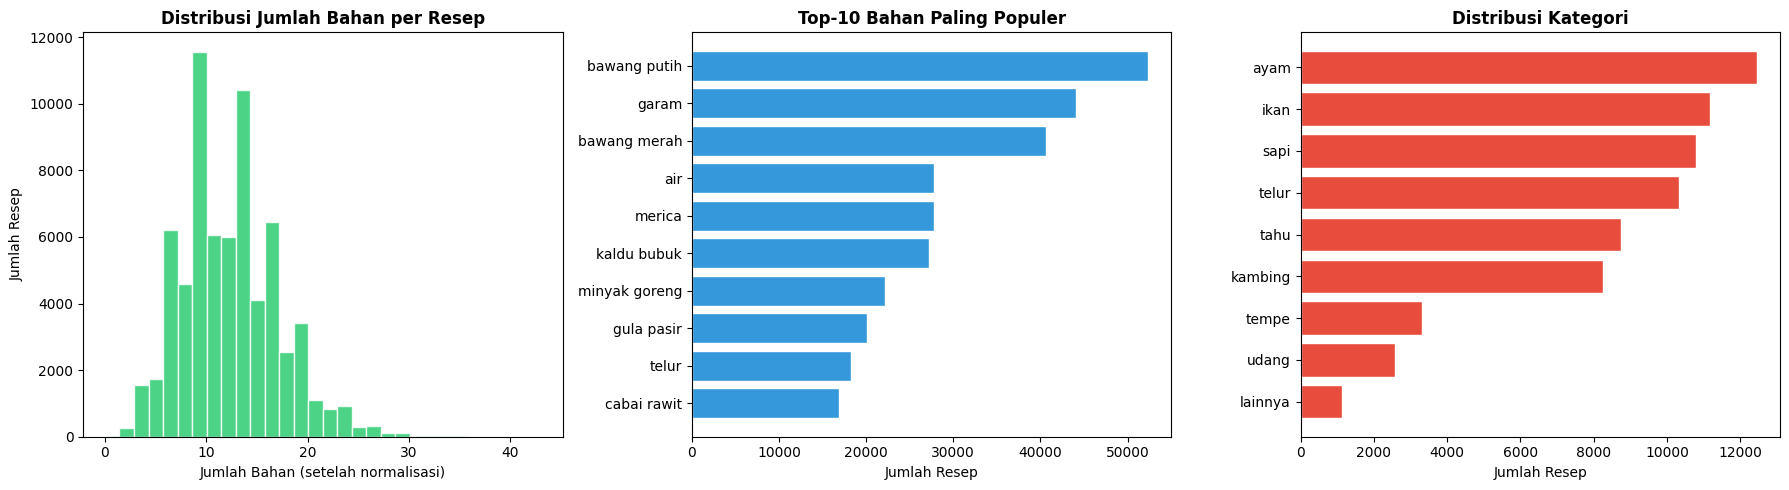

  [SAVED] Grafik analisis EDA disimpan di: D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\eda_overview.png
[OK] Cell 6 selesai: preprocessing korpus dan analisis EDA selesai.


In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6: Corpus Preprocessing Execution & EXPLORATORY DATA ANALYSIS (EDA)
# ═══════════════════════════════════════════════════════════════════════════════

print("[PREPROCESS] Menjalankan NLP pipeline pada seluruh korpus ...")

all_sets = []
core_sets = []
ir_token_sets = []
ir_texts = []

raw_lists = df_all["ingredients_raw_list"].tolist()
for ingr_raw in tqdm(raw_lists, total=len(raw_lists), desc="Parsing bahan"):
    result = PARSER.extract_ingredients_from_recipe(ingr_raw)
    all_sets.append(result["ingredients_all_set"])
    core_sets.append(result["ingredients_core_set"])
    ir_token_sets.append(result["ingredients_ir_tokens"])
    ir_texts.append(result["ingredients_ir_text"])

df_all["ingredients_all_set"] = all_sets
df_all["ingredients_core_set"] = core_sets
df_all["ingredients_ir_tokens"] = ir_token_sets
df_all["ingredients_ir_text"] = ir_texts

# Also create title IR text
df_all["title_ir_text"] = df_all["title_clean"].apply(
    lambda t: re.sub(r'[^a-z\s]', '', t.lower()).strip() if isinstance(t, str) else ""
)

print(f"\n  [STATS] Preprocessing selesai untuk {len(df_all)} resep.")

# ── Quick EDA ────────────────────────────────────────────────────────────────
print("\n" + "─" * 60)
print("  [EDA] EXPLORATORY DATA ANALYSIS (EDA)")
print("─" * 60)

# Distribution of ingredient counts
ingr_counts = df_all["ingredients_all_set"].apply(len)
print(f"\n  Jumlah bahan per resep:")
print(f"    Mean   : {ingr_counts.mean():.1f}")
print(f"    Median : {ingr_counts.median():.1f}")
print(f"    Min    : {ingr_counts.min()}")
print(f"    Max    : {ingr_counts.max()}")

# Top-20 most popular ingredients
all_ingr_counter = Counter()
for s in df_all["ingredients_all_set"]:
    all_ingr_counter.update(s)

print(f"\n  Top-20 Bahan Paling Populer:")
for i, (ingr, cnt) in enumerate(all_ingr_counter.most_common(20), 1):
    print(f"    {i:>2}. {ingr:<25s} : {cnt:>5} resep")

# Category distribution
print(f"\n  Distribusi Kategori:")
for cat, cnt in df_all["main_category"].value_counts().items():
    print(f"    {cat:<12s}: {cnt:>5}")

# Source distribution
print(f"\n  Distribusi Sumber:")
for src, cnt in df_all["source"].value_counts().items():
    print(f"    {src:<20s}: {cnt:>5}")

# Example: raw vs IR representation
print(f"\n  Contoh Representasi Raw vs IR:")
sample = df_all.iloc[0]
print(f"    Judul    : {sample['title_clean']}")
print(f"    Raw[0:3] : {sample['ingredients_raw_list'][:3]}")
print(f"    IR text  : {sample['ingredients_ir_text'][:120]}...")

# ── Visualisasi EDA ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribusi jumlah bahan
axes[0].hist(ingr_counts, bins=30, color="#2ecc71", edgecolor="white", alpha=0.85)
axes[0].set_title("Distribusi Jumlah Bahan per Resep", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jumlah Bahan (setelah normalisasi)")
axes[0].set_ylabel("Jumlah Resep")

# 2. Top-10 bahan
top10 = all_ingr_counter.most_common(10)
axes[1].barh([x[0] for x in top10][::-1], [x[1] for x in top10][::-1], color="#3498db", edgecolor="white")
axes[1].set_title("Top-10 Bahan Paling Populer", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jumlah Resep")

# 3. Kategori
cat_counts = df_all["main_category"].value_counts()
axes[2].barh(cat_counts.index[::-1], cat_counts.values[::-1], color="#e74c3c", edgecolor="white")
axes[2].set_title("Distribusi Kategori", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Jumlah Resep")

plt.tight_layout()
eda_path = ENV.ARTIFACT_DIR / "eda_overview.png"
plt.savefig(eda_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"  [SAVED] Grafik analisis EDA disimpan di: {eda_path}")
print("[OK] Cell 6 selesai: preprocessing korpus dan analisis EDA selesai.")

In [7]:
# ==============================================================================
# CELL 7: Pemodelan Information Retrieval (Set-Overlap, TF-IDF, BM25, SisaRasa Hybrid)
# ==============================================================================

from abc import ABC, abstractmethod
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
import numpy as np


def _identity_token_func(x):
    """Fungsi identitas tingkat modul agar CountVectorizer dapat diserialisasi via pickle."""
    return x


class BaseRetriever(ABC):
    name: str = "Base"

    @abstractmethod
    def index(self, corpus_df: pd.DataFrame):
        pass

    @abstractmethod
    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        """Return list of (doc_id, score) sorted by score desc."""
        pass


# -- Model 1: Set-Overlap / Jaccard Baseline -----------------------------------

class SetOverlapRetriever(BaseRetriever):
    name = "Set-Overlap"

    def __init__(self, parser: IndonesianIngredientParser):
        self.parser = parser
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.doc_ingr_matrix = None
        self.doc_lengths = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        core_lists = [list(s) for s in corpus_df["ingredients_core_set"]]
        self.vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_ingr_matrix = self.vectorizer.fit_transform(core_lists)
        self.doc_lengths = np.array(self.doc_ingr_matrix.sum(axis=1)).flatten()

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_core = q_parsed["ingredients_core_set"]
        if not q_core:
            return []

        q_vec = self.vectorizer.transform([list(q_core)])
        intersections = np.array(self.doc_ingr_matrix.dot(q_vec.T).toarray()).flatten()
        q_len = len(q_core)
        unions = self.doc_lengths + q_len - intersections

        with np.errstate(divide='ignore', invalid='ignore'):
            jaccard = np.where(unions > 0, intersections / unions, 0.0)

        top_indices = np.argsort(jaccard)[::-1][:top_k]
        return [(self.doc_ids[i], float(jaccard[i])) for i in top_indices if jaccard[i] > 0]


# -- Model 2: TF-IDF + Cosine Similarity Baseline -----------------------------

class TfidfCosineRetriever(BaseRetriever):
    name = "TF-IDF Cosine"

    def __init__(self, parser: IndonesianIngredientParser, w_ingr: float = 0.70, w_title: float = 0.30):
        self.parser = parser
        self.w_ingr = w_ingr
        self.w_title = w_title
        self.doc_ids: List[str] = []
        self.vectorizer_ingr = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", lowercase=False)
        self.vectorizer_title = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", lowercase=False)
        self.tfidf_ingr = None
        self.tfidf_title = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        ingr_texts = corpus_df["ingredients_ir_text"].fillna("").tolist()
        title_texts = corpus_df["title_ir_text"].fillna("").tolist()
        self.tfidf_ingr = self.vectorizer_ingr.fit_transform(ingr_texts)
        self.tfidf_title = self.vectorizer_title.fit_transform(title_texts)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip():
            return []

        q_vec_ingr = self.vectorizer_ingr.transform([q_ir_text])
        sim_ingr = cosine_similarity(q_vec_ingr, self.tfidf_ingr).flatten()

        q_vec_title = self.vectorizer_title.transform([q_ir_text])
        sim_title = cosine_similarity(q_vec_title, self.tfidf_title).flatten()

        scores = self.w_ingr * sim_ingr + self.w_title * sim_title
        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]

    def get_scores_array(self, query_str: str) -> np.ndarray:
        """Return full score array untuk model hybrid."""
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip():
            return np.zeros(len(self.doc_ids))
        q_vec_ingr = self.vectorizer_ingr.transform([q_ir_text])
        sim_ingr = cosine_similarity(q_vec_ingr, self.tfidf_ingr).flatten()
        q_vec_title = self.vectorizer_title.transform([q_ir_text])
        sim_title = cosine_similarity(q_vec_title, self.tfidf_title).flatten()
        return self.w_ingr * sim_ingr + self.w_title * sim_title


# -- Model 3: Okapi BM25 (Vectorized Sparse Matrix) ---------------------------

class BM25Retriever(BaseRetriever):
    name = "BM25"

    def __init__(self, parser: IndonesianIngredientParser, k1: float = 1.2, b: float = 0.4):
        self.parser = parser
        self.k1 = k1
        self.b = b
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.bm25_matrix: Optional[csr_matrix] = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        texts = corpus_df["ingredients_ir_text"].fillna("").tolist()

        self.vectorizer = CountVectorizer(
            token_pattern=r"(?u)\b\w+\b",
            lowercase=False
        )
        tf_matrix = self.vectorizer.fit_transform(texts)
        N, V = tf_matrix.shape

        doc_len = np.array(tf_matrix.sum(axis=1)).flatten()
        avgdl = float(doc_len.mean()) if N > 0 else 1.0

        # Document frequency df
        df = np.bincount(tf_matrix.indices, minlength=V)

        # Okapi BM25 IDF dengan smoothing +1.0
        idf = np.log((N - df + 0.5) / (df + 0.5) + 1.0)

        # Precompute bobot BM25 sparse matrix
        row_indices = np.repeat(np.arange(N), np.diff(tf_matrix.indptr))
        tf_vals = tf_matrix.data
        len_norm = 1.0 - self.b + self.b * (doc_len / (avgdl + 1e-9))
        denom = tf_vals + self.k1 * len_norm[row_indices]
        bm25_data = (tf_vals * (self.k1 + 1.0) / denom) * idf[tf_matrix.indices]

        self.bm25_matrix = csr_matrix((bm25_data, tf_matrix.indices, tf_matrix.indptr), shape=tf_matrix.shape)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        scores = self.get_scores_array(query_str)
        if scores.size == 0 or np.all(scores == 0):
            return []
        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]

    def get_scores_array(self, query_str: str) -> np.ndarray:
        """Return full score array untuk model hybrid via perkalian matriks sparse."""
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip() or self.bm25_matrix is None:
            return np.zeros(len(self.doc_ids))

        q_vec = self.vectorizer.transform([q_ir_text])
        if q_vec.nnz == 0:
            return np.zeros(len(self.doc_ids))

        scores = np.array(self.bm25_matrix.dot(q_vec.T).toarray()).ravel()
        return scores


# -- Model 4: SisaRasa Hybrid Culinary Ranking (Proposed Method) ---------------

class SisaRasaHybridRetriever(BaseRetriever):
    name = "SisaRasa Hybrid"

    MAIN_PROTEINS = frozenset({
        "ayam", "daging sapi", "daging kambing", "ikan", "udang",
        "cumi", "telur", "tahu", "tempe",
    })

    def __init__(self, parser: IndonesianIngredientParser,
                 bm25_retriever: BM25Retriever,
                 tfidf_retriever: TfidfCosineRetriever,
                 w1: float = 0.10, w2: float = 0.05, w3: float = 0.20,
                 w4: float = 0.20, w_jaccard: float = 0.35,
                 w5: float = 0.10, w_prot: float = 0.25):
        self.parser = parser
        self.bm25_retriever = bm25_retriever
        self.tfidf_retriever = tfidf_retriever
        self.w1 = w1
        self.w2 = w2
        self.w3 = w3
        self.w4 = w4
        self.w_jaccard = w_jaccard
        self.w5 = w5
        self.w_prot = w_prot
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.doc_ingr_matrix = None
        self.doc_core_len = None
        self.protein_vectorizer: Optional[CountVectorizer] = None
        self.doc_protein_matrix = None
        self.doc_has_protein = None
        self.epsilon = 1e-9

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        core_lists = [list(s) for s in corpus_df["ingredients_core_set"]]

        # 1. Matriks biner sparse seluruh bahan inti
        self.vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_ingr_matrix = self.vectorizer.fit_transform(core_lists)
        self.doc_core_len = np.array(self.doc_ingr_matrix.sum(axis=1)).flatten()

        # 2. Matriks biner sparse khusus Protein Utama
        doc_proteins = [[p for p in s if p in self.MAIN_PROTEINS] for s in corpus_df["ingredients_core_set"]]
        self.protein_vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_protein_matrix = self.protein_vectorizer.fit_transform(doc_proteins)
        self.doc_has_protein = (np.array(self.doc_protein_matrix.sum(axis=1)).flatten() > 0)

    def _min_max_normalize(self, arr: np.ndarray) -> np.ndarray:
        mn, mx = arr.min(), arr.max()
        if mx - mn < 1e-12:
            return np.zeros_like(arr)
        return (arr - mn) / (mx - mn)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_core = q_parsed["ingredients_core_set"]
        if not q_core:
            return []

        n = len(self.doc_ids)

        # 1. Skor probabilistik leksikal BM25 (ternormalisasi)
        bm25_raw = self.bm25_retriever.get_scores_array(query_str)
        bm25_norm = self._min_max_normalize(bm25_raw)

        # 2. Skor kecocokan vektor TF-IDF (ternormalisasi)
        tfidf_raw = self.tfidf_retriever.get_scores_array(query_str)
        tfidf_norm = self._min_max_normalize(tfidf_raw)

        # 3. Vektorisasi Set Operations via Perkalian Matriks Sparse
        q_vec = self.vectorizer.transform([list(q_core)])
        intersection = np.array(self.doc_ingr_matrix.dot(q_vec.T).toarray()).flatten()

        q_core_len = len(q_core)
        # Smoothing pada penyebut core_coverage untuk meredam resep terlalu pendek (doc_core_len < 2)
        denom_len = np.maximum(self.doc_core_len, 2.0 if q_core_len >= 2 else 1.0)
        core_coverage = intersection / (denom_len + self.epsilon)
        query_util = intersection / (q_core_len + self.epsilon)

        unions = self.doc_core_len + q_core_len - intersection
        with np.errstate(divide='ignore', invalid='ignore'):
            jaccard = np.where(unions > 0, intersection / unions, 0.0)

        missing = np.maximum(0, self.doc_core_len - intersection - 2)
        missing_penalty = missing / (self.doc_core_len + 3)

        # 4. Main Protein Alignment
        q_proteins = q_core & self.MAIN_PROTEINS
        protein_alignment = np.zeros(n)
        if q_proteins:
            q_prot_vec = self.protein_vectorizer.transform([list(q_proteins)])
            protein_inter = np.array(self.doc_protein_matrix.dot(q_prot_vec.T).toarray()).flatten()
            protein_alignment[protein_inter > 0] = 1.0
            protein_alignment[(protein_inter == 0) & self.doc_has_protein] = -0.5

        # 5. Masking Penalti jika bahan cocok < 2 saat query memiliki >= 2 bahan inti
        min_match_mask = (intersection >= 2) if q_core_len >= 2 else (intersection >= 1)

        # 6. Formula Skor Hybrid Terkalibrasi
        scores = (self.w1 * bm25_norm
                  + self.w2 * tfidf_norm
                  + self.w3 * core_coverage
                  + self.w4 * query_util
                  + self.w_jaccard * jaccard
                  - self.w5 * missing_penalty
                  + self.w_prot * protein_alignment)
        scores = np.where(min_match_mask, scores, scores * 0.25)

        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]


print("[OK] Cell 7 selesai: 4 model temu kembali informasi berhasil diimplementasikan.")


[OK] Cell 7 selesai: 4 model temu kembali informasi berhasil diimplementasikan.


In [8]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8: Indexing Korpus & Pengukuran Resource (Waktu & Penggunaan Memori)
# ═══════════════════════════════════════════════════════════════════════════════

import sys

def measure_size_mb(obj) -> float:
    """Rough memory estimate in MB."""
    try:
        return sys.getsizeof(pickle.dumps(obj)) / (1024 * 1024)
    except Exception:
        return 0.0


print("[INDEX] Membangun indeks 4 model retrieval ...\n")

# Instantiate models
model_setoverlap = SetOverlapRetriever(PARSER)
model_tfidf = TfidfCosineRetriever(PARSER)
model_bm25 = BM25Retriever(PARSER, k1=1.2, b=0.4)
model_hybrid = SisaRasaHybridRetriever(PARSER, model_bm25, model_tfidf)

models = {
    "Set-Overlap": model_setoverlap,
    "TF-IDF Cosine": model_tfidf,
    "BM25": model_bm25,
    "SisaRasa Hybrid": model_hybrid,
}

index_stats = []
for name, model in models.items():
    t0 = time.perf_counter()
    model.index(df_all)
    t1 = time.perf_counter()
    mem = measure_size_mb(model)
    index_stats.append({"Model": name, "Index Time (s)": round(t1 - t0, 3), "Size (MB)": round(mem, 2)})
    print(f"  [OK] {name:<20s}: {t1-t0:.3f}s, ~{mem:.1f} MB")

df_index_stats = pd.DataFrame(index_stats)
print(f"\n{df_index_stats.to_string(index=False)}")

# Quick sanity check
test_query = "ayam, bawang merah, bawang putih, kecap manis"
print(f"\n  [QUERY] SANITY CHECK QUERY: '{test_query}'")
for name, model in models.items():
    results = model.retrieve(test_query, top_k=3)
    if results:
        top_title = df_all.loc[df_all["doc_id"] == results[0][0], "title_clean"].iloc[0]
        print(f"    {name:<20s} → #{1}: {top_title} (skor: {results[0][1]:.4f})")
    else:
        print(f"    {name:<20s} → (no results)")

print("[OK] Cell 8 selesai: seluruh indeks model temu kembali berhasil dibangun.")

[INDEX] Membangun indeks 4 model retrieval ...

  [OK] Set-Overlap         : 1.110s, ~10.2 MB
  [OK] TF-IDF Cosine       : 1.880s, ~27.8 MB
  [OK] BM25                : 1.489s, ~23.9 MB
  [OK] SisaRasa Hybrid     : 0.881s, ~62.0 MB

          Model  Index Time (s)  Size (MB)
    Set-Overlap           1.110      10.19
  TF-IDF Cosine           1.880      27.84
           BM25           1.489      23.94
SisaRasa Hybrid           0.881      62.03

  [QUERY] SANITY CHECK QUERY: 'ayam, bawang merah, bawang putih, kecap manis'
    Set-Overlap          → #1: Ayam Kecap (skor: 1.0000)
    TF-IDF Cosine        → #1: Ayam Kecap (skor: 0.6929)
    BM25                 → #1: Semur Ayam Bumbu Merah (skor: 7.6233)
    SisaRasa Hybrid      → #1: Ayam Kecap (skor: 1.1482)
[OK] Cell 8 selesai: seluruh indeks model temu kembali berhasil dibangun.


In [9]:
# ==============================================================================
# CELL 9: Generator Stratified Benchmark Queries (Skenario A-D) & Automated Qrels
# ==============================================================================

class BenchmarkQueryGenerator:
    """Pembangkit query evaluasi stratified berdasarkan 4 skenario."""

    def __init__(self, corpus_df: pd.DataFrame, parser: IndonesianIngredientParser, seed: int = 42):
        self.corpus = corpus_df
        self.parser = parser
        self.rng = np.random.RandomState(seed)

    def _sample_ingredients_from_corpus(self, n_ingredients: int, category: Optional[str] = None) -> str:
        """Sample bahan dari resep nyata di korpus."""
        if category:
            pool = self.corpus[self.corpus["main_category"] == category]
            if pool.empty:
                pool = self.corpus
        else:
            pool = self.corpus

        idx = self.rng.randint(0, len(pool))
        recipe = pool.iloc[idx]
        core = list(recipe["ingredients_core_set"])
        if len(core) < n_ingredients:
            selected = core
        else:
            self.rng.shuffle(core)
            selected = core[:n_ingredients]
        return ", ".join(selected)

    def generate_scenario_a(self, n: int = 12) -> List[Dict]:
        """Skenario A: Sisa Kulkas Minimalis (2-3 bahan inti)."""
        handcrafted = [
            "telur, tahu, kecap manis",
            "tempe, cabai rawit, bawang putih",
            "ayam, bawang merah, garam",
            "tahu, bayam, bawang putih",
            "telur, wortel, bawang merah",
            "udang, bawang putih, cabai",
            "tempe, kecap manis, cabai rawit",
            "telur, kangkung",
            "tahu, cabai merah, tomat",
            "ikan, kunyit, serai",
            "daging sapi, bawang bombay, merica",
            "ayam, jahe, bawang putih",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"A{i+1:02d}", "scenario": "A", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(2, 4))
            queries.append({"query_id": f"A{len(queries)+1:02d}", "scenario": "A", "query_text": q})
        return queries

    def generate_scenario_b(self, n: int = 12) -> List[Dict]:
        """Skenario B: Masak Harian Standar (4-6 bahan inti)."""
        handcrafted = [
            "ayam, bawang merah, bawang putih, kecap manis, merica, kentang",
            "tempe, cabai merah, bawang merah, bawang putih, tomat, kecap manis",
            "udang, bawang putih, mentimun, cabai rawit, serai, santan",
            "telur, wortel, kubis, bawang putih, kecap manis, saus tiram",
            "tahu, jamur, wortel, bawang putih, saus tiram, daun bawang",
            "daging sapi, bawang bombay, wortel, kentang, tomat, seledri",
            "ikan, kunyit, cabai merah, bawang merah, tomat, serai",
            "ayam, santan, serai, daun jeruk, lengkuas, cabai",
            "tempe, buncis, bawang merah, bawang putih, cabai hijau, terasi",
            "telur, bayam, wortel, bawang putih, bawang merah, jagung",
            "tahu, udang, tauge, kecap manis, bawang putih, saus tiram",
            "daging sapi, kentang, wortel, bawang bombay, tomat, seledri",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"B{i+1:02d}", "scenario": "B", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(4, 7))
            queries.append({"query_id": f"B{len(queries)+1:02d}", "scenario": "B", "query_text": q})
        return queries

    def generate_scenario_c(self, n: int = 12) -> List[Dict]:
        """Skenario C: Kombinasi Bahan Lengkap (7-10 bahan inti)."""
        handcrafted = [
            "ayam, santan, serai, lengkuas, daun jeruk, kunyit, cabai merah, bawang merah, bawang putih, kemiri",
            "daging sapi, santan, serai, lengkuas, kunyit, jahe, cabai merah, bawang merah, bawang putih, kelapa",
            "ikan, kunyit, cabai merah, bawang merah, bawang putih, tomat, serai, daun kunyit, kemiri, asam jawa",
            "ayam, kentang, wortel, bawang bombay, bawang putih, tomat, seledri, daun salam, merica, pala",
            "udang, santan, cabai merah, bawang merah, bawang putih, kunyit, serai, lengkuas, daun jeruk",
            "tempe, tahu, cabai merah, bawang merah, bawang putih, tomat, terasi, kecap manis, daun jeruk, serai",
            "daging kambing, santan, serai, lengkuas, jahe, kunyit, cabai, ketumbar, jintan, kayu manis",
            "ayam, bawang merah, bawang putih, jahe, kunyit, ketumbar, kemiri, santan, serai, daun salam",
            "ikan, bawang merah, bawang putih, cabai merah, cabai rawit, tomat, terasi, serai, lengkuas, kunyit",
            "telur, santan, bawang merah, bawang putih, cabai, kunyit, daun jeruk, serai, lengkuas",
            "daging sapi, bawang merah, bawang putih, cabai, jahe, serai, kecap manis, lengkuas, daun salam, merica",
            "udang, cabai merah, bawang merah, bawang putih, tomat, terasi, lengkuas, serai, daun jeruk, kunyit",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"C{i+1:02d}", "scenario": "C", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(7, 11))
            queries.append({"query_id": f"C{len(queries)+1:02d}", "scenario": "C", "query_text": q})
        return queries

    def generate_scenario_d(self, n: int = 12) -> List[Dict]:
        """Skenario D: Noisy / Colloquial User Input."""
        handcrafted = [
            "2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, santen kara, daun jeruk",
            "telor 3 btr, terigu 200gr, mentega, gula pasir, vanili",
            "1/2 kg daging sapi, 2 bh kentang, bw merah, bw putih, kecap bango",
            "tempe 1 papan, lombok rawit, bamer 5 siung, baput 3 siung, santen, gula jawa",
            "udang kupas 250gr, 3 siung baput, cabe ijo, saori, minyak sayur",
            "3 potong tahu putih, telor 2 butir, terigu, bawang pth, cabe rawit",
            "1 ekor ikan nila, kunir, laos, sereh, daun salam, cabe merah besar",
            "dada ayam fillet 500g, bw bombai, saus tomat, kecap, merica bubuk",
            "toge 1 ikat, tahu 2 buah, bamer, baput, kecap, cabe rawit",
            "4 butir telor, sledri, daun prei, royco, minyak, garam secukupnya",
            "kambing 1 kg, santen 500 ml, laos, sereh, jinten, kayu manis, pekak",
            "ikan tongkol 3 ptg, asem jawa, cabe, bamer, tomat, terasi, gula merah",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"D{i+1:02d}", "scenario": "D", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(3, 8))
            queries.append({"query_id": f"D{len(queries)+1:02d}", "scenario": "D", "query_text": q})
        return queries

    def generate_all(self, n_per_scenario: int = 12) -> List[Dict]:
        all_queries = []
        all_queries.extend(self.generate_scenario_a(n_per_scenario))
        all_queries.extend(self.generate_scenario_b(n_per_scenario))
        all_queries.extend(self.generate_scenario_c(n_per_scenario))
        all_queries.extend(self.generate_scenario_d(n_per_scenario))
        return all_queries


# -- Graded Relevance Judgment Generator (Qrels) ------------------------------

class QrelGenerator:
    """Pembangkit Graded Relevance Judgments (0-3) berdasarkan kriteria kuliner terstandardisasi."""

    MAIN_PROTEIN_KEYWORDS = frozenset({
        "ayam", "daging sapi", "daging kambing", "ikan", "udang",
        "cumi", "telur", "tahu", "tempe",
    })

    def __init__(self, corpus_df: pd.DataFrame, parser: IndonesianIngredientParser):
        self.corpus = corpus_df
        self.parser = parser
        self._doc_id_to_idx = {did: i for i, did in enumerate(corpus_df["doc_id"].tolist())}
        # Precompute set bahan inti dan protein untuk pencarian instan
        self._doc_core_sets = [set(s) for s in corpus_df["ingredients_core_set"].tolist()]
        self._doc_proteins = [s & self.MAIN_PROTEIN_KEYWORDS for s in self._doc_core_sets]

    def judge(self, query_text: str, doc_id: str) -> int:
        """Assign relevance grade 0-3 untuk pasangan (query, document)."""
        idx = self._doc_id_to_idx.get(doc_id)
        if idx is None:
            return 0
        d_core = self._doc_core_sets[idx]
        d_proteins = self._doc_proteins[idx]

        q_parsed = self.parser.parse_query(query_text)
        q_core = q_parsed["ingredients_core_set"]
        if not q_core or not d_core:
            return 0

        intersection = q_core & d_core
        inter_len = len(intersection)
        core_coverage = inter_len / (len(d_core) + 1e-9)
        query_util = inter_len / (len(q_core) + 1e-9)

        # Cek kesesuaian protein utama jika query mengandung protein
        q_proteins = q_core & self.MAIN_PROTEIN_KEYWORDS
        protein_match = bool(q_proteins & d_proteins) if q_proteins else True

        # Grade 3: Highly Relevant (Protein cocok, cakupan bahan tinggi, utilisasi tinggi)
        if protein_match and core_coverage >= 0.65 and query_util >= 0.60:
            return 3
        # Grade 2: Moderately Relevant (Protein cocok, minimal 2 bahan inti, cakupan memadai)
        if protein_match and core_coverage >= 0.45 and inter_len >= 2 and query_util >= 0.50:
            return 2
        # Grade 1: Marginally Relevant (Minimal 2 bahan inti cocok, cakupan parsial)
        if inter_len >= 2 and core_coverage >= 0.30:
            return 1
        # Grade 0: Not Relevant
        return 0

    def generate_qrels_for_query(self, query_text: str, candidate_doc_ids: List[str]) -> Dict[str, int]:
        """Generate relevance grades untuk seluruh kandidat dokumen."""
        return {doc_id: self.judge(query_text, doc_id) for doc_id in candidate_doc_ids}


# -- Eksekusi Pembangkitan Query & Qrels ----------------------------------------
print("[EVAL] Membangkitkan Benchmark Queries ...")
query_gen = BenchmarkQueryGenerator(df_all, PARSER, seed=RANDOM_SEED)
benchmark_queries = query_gen.generate_all(n_per_scenario=12)
print(f"  Total queries: {len(benchmark_queries)}")
for scenario in ["A", "B", "C", "D"]:
    n = sum(1 for q in benchmark_queries if q["scenario"] == scenario)
    print(f"    Skenario {scenario}: {n} queries")

print("\n[EVAL] Membangkitkan Graded Relevance Judgments (Qrels) ...")
qrel_gen = QrelGenerator(df_all, PARSER)

POOL_DEPTH = 30
all_qrels = {}

for q_info in tqdm(benchmark_queries, desc="[EVAL] Qrels Pooling"):
    qid = q_info["query_id"]
    qtxt = q_info["query_text"]

    candidate_pool = set()
    for model in models.values():
        results = model.retrieve(qtxt, top_k=POOL_DEPTH)
        candidate_pool.update(doc_id for doc_id, _ in results)

    qrels = qrel_gen.generate_qrels_for_query(qtxt, list(candidate_pool))
    all_qrels[qid] = qrels

total_judgments = sum(len(v) for v in all_qrels.values())
grade_dist = Counter()
for qrels in all_qrels.values():
    grade_dist.update(qrels.values())
print(f"\n  Total pasangan query-dokumen yang dinilai (Qrels): {total_judgments}")
print(f"  Distribusi Graded Relevance (0-3): {dict(sorted(grade_dist.items()))}")
print("[OK] Cell 9 selesai: 48 query benchmark dan matriks Qrels berhasil dibangun.")


[EVAL] Membangkitkan Benchmark Queries ...
  Total queries: 48
    Skenario A: 12 queries
    Skenario B: 12 queries
    Skenario C: 12 queries
    Skenario D: 12 queries

[EVAL] Membangkitkan Graded Relevance Judgments (Qrels) ...


[EVAL] Qrels Pooling:   0%|          | 0/48 [00:00<?, ?it/s]


  Total pasangan query-dokumen yang dinilai (Qrels): 3607
  Distribusi Graded Relevance (0-3): {0: 349, 1: 1266, 2: 1039, 3: 953}
[OK] Cell 9 selesai: 48 query benchmark dan matriks Qrels berhasil dibangun.


[EVAL] Menjalankan benchmark evaluasi seluruh model ...

  Evaluating Set-Overlap ...
  Evaluating TF-IDF Cosine ...
  Evaluating BM25 ...
  Evaluating SisaRasa Hybrid ...

════════════════════════════════════════════════════════════════════════════════
  [STATS] TABEL KOMPARASI PERFORMA MODEL (OVERALL BENCHMARK)
════════════════════════════════════════════════════════════════════════════════
                    P@5     R@5    F1@5  nDCG@5    P@10    R@10   F1@10  nDCG@10  MAP@10     MRR  Latency (ms)
Model                                                                                                         
Set-Overlap      0.8708  0.1283  0.2091  0.8668  0.8583  0.2542  0.3588   0.8576  0.8214  0.9354        9.3437
TF-IDF Cosine    0.6875  0.0875  0.1480  0.6196  0.6396  0.1577  0.2374   0.6000  0.5469  0.8082       77.1667
BM25             0.5958  0.0786  0.1277  0.4769  0.5521  0.1436  0.2056   0.4693  0.4728  0.8408       18.8032
SisaRasa Hybrid  0.9458  0.1522  0.2380  0.8857  

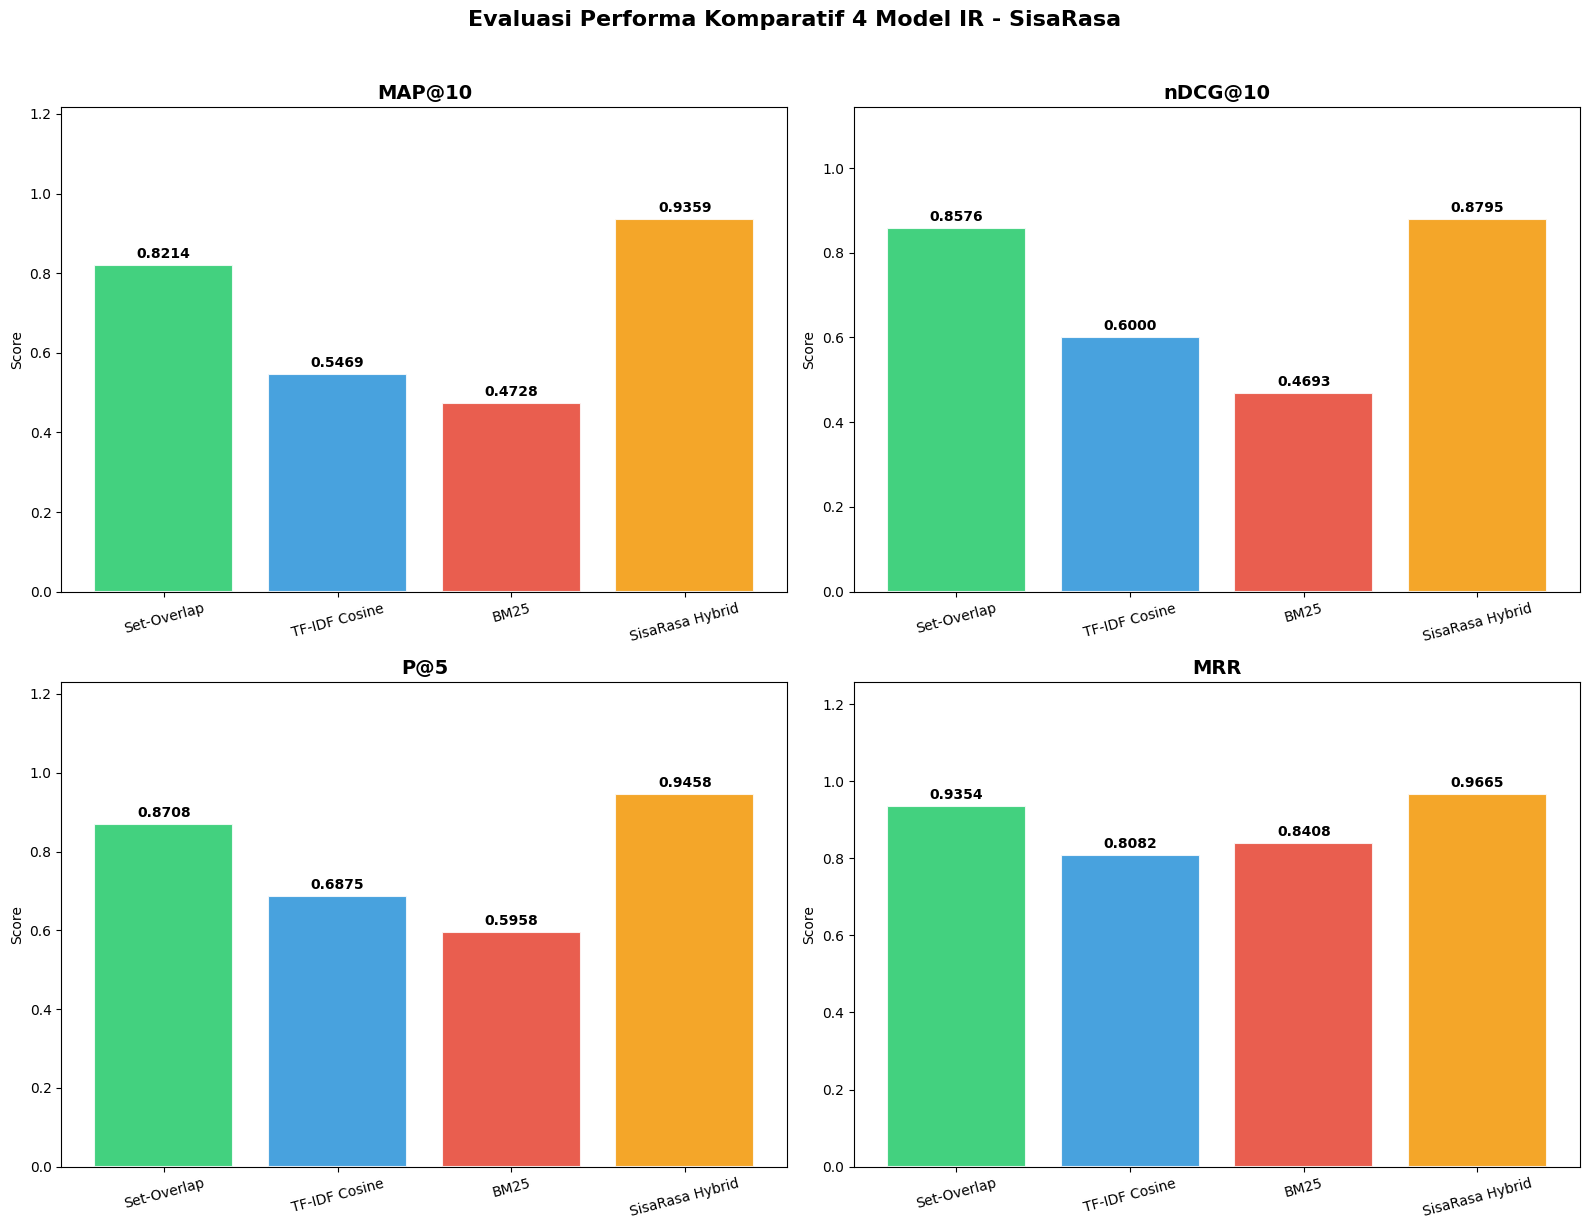


  [SAVED] Grafik komparasi performa model disimpan di: D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\model_comparison.png


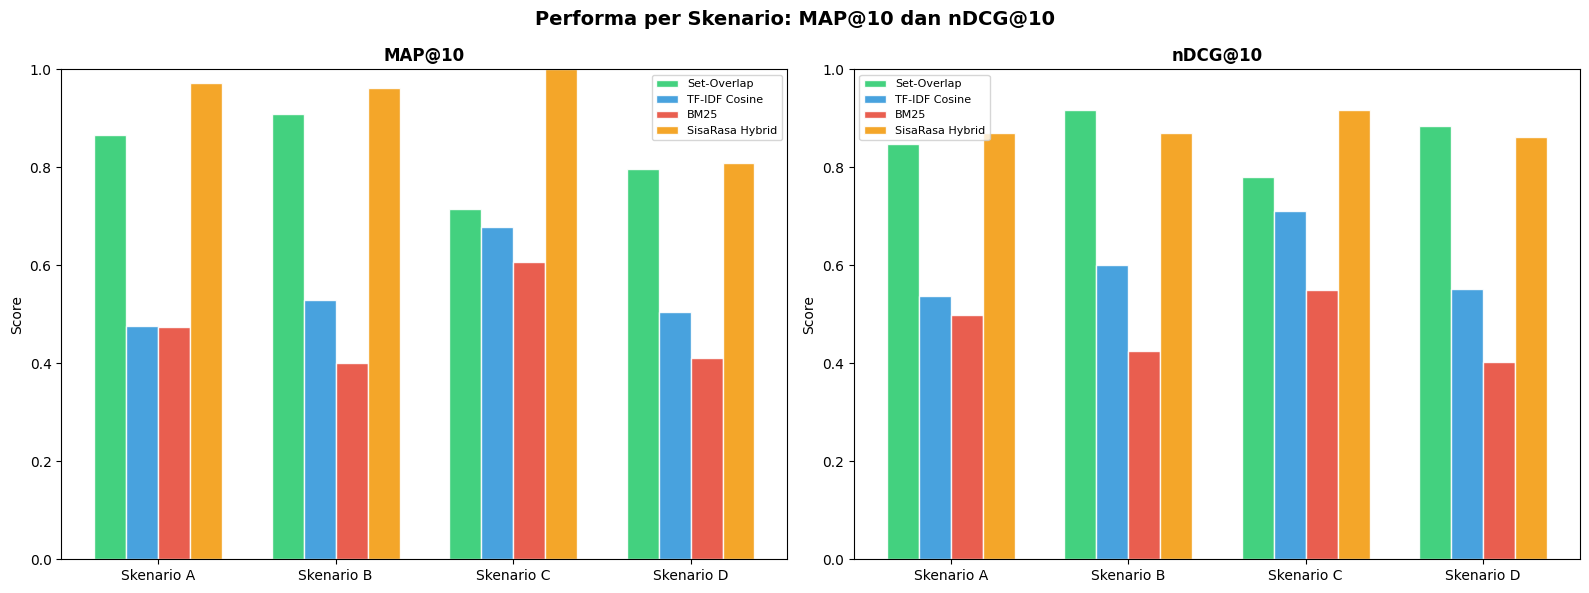

  [SAVED] Grafik komparasi per skenario disimpan di: D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\scenario_comparison.png
[OK] Cell 10 selesai: kalkulasi metrik evaluasi STKI dan visualisasi selesai.


In [10]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10: Mesin Evaluasi Metrik IR (P, R, F1, MAP@10, MRR, nDCG@5, nDCG@10)
# ═══════════════════════════════════════════════════════════════════════════════

import math
from collections import defaultdict


class IRMetricsEvaluator:
    """Mesin kalkulasi metrik Information Retrieval terstandardisasi TREC."""

    BINARY_THRESHOLD = 2  # Grade >= 2 dinilai relevan untuk metrik biner

    @staticmethod
    def precision_at_k(retrieved_grades: List[int], k: int, threshold: int = 2) -> float:
        top = retrieved_grades[:k]
        if not top:
            return 0.0
        return sum(1 for g in top if g >= threshold) / k

    @staticmethod
    def recall_at_k(retrieved_grades: List[int], k: int, total_relevant: int, threshold: int = 2) -> float:
        if total_relevant == 0:
            return 0.0
        top = retrieved_grades[:k]
        return sum(1 for g in top if g >= threshold) / total_relevant

    @staticmethod
    def f1_at_k(precision: float, recall: float) -> float:
        if precision + recall == 0:
            return 0.0
        return 2 * (precision * recall) / (precision + recall)

    @staticmethod
    def average_precision_at_k(retrieved_grades: List[int], k: int, total_relevant: int, threshold: int = 2) -> float:
        if total_relevant == 0:
            return 0.0
        top = retrieved_grades[:k]
        num_rel = 0
        sum_prec = 0.0
        for i, g in enumerate(top):
            if g >= threshold:
                num_rel += 1
                sum_prec += num_rel / (i + 1)
        return sum_prec / min(k, total_relevant)

    @staticmethod
    def reciprocal_rank(retrieved_grades: List[int], threshold: int = 2) -> float:
        for i, g in enumerate(retrieved_grades):
            if g >= threshold:
                return 1.0 / (i + 1)
        return 0.0

    @staticmethod
    def dcg_at_k(retrieved_grades: List[int], k: int) -> float:
        top = retrieved_grades[:k]
        dcg = 0.0
        for i, rel in enumerate(top):
            dcg += (2**rel - 1) / math.log2(i + 2)
        return dcg

    @staticmethod
    def ndcg_at_k(retrieved_grades: List[int], k: int, all_grades: List[int]) -> float:
        dcg = IRMetricsEvaluator.dcg_at_k(retrieved_grades, k)
        ideal = sorted(all_grades, reverse=True)
        idcg = IRMetricsEvaluator.dcg_at_k(ideal, k)
        if idcg == 0:
            return 0.0
        return dcg / idcg

    def evaluate_model(self, model: BaseRetriever, queries: List[Dict],
                       qrels: Dict[str, Dict[str, int]], k_values: List[int] = [5, 10]) -> Tuple[Dict, Dict[str, Dict]]:
        """Evaluasi model satu kali jalan (single-pass) untuk seluruh query,
        menghasilkan metrik overall dan breakdown per skenario secara simultan.
        """
        max_k = max(k_values)
        per_query_records = []

        for q_info in queries:
            qid = q_info["query_id"]
            qtxt = q_info["query_text"]
            scenario = q_info.get("scenario", "default")
            q_qrels = qrels.get(qid, {})

            # Retrieve satu kali saja per query
            t0 = time.perf_counter()
            retrieved = model.retrieve(qtxt, top_k=max_k)
            t1 = time.perf_counter()
            latency_ms = (t1 - t0) * 1000

            # Nilai relevance grade
            retrieved_grades = [q_qrels.get(doc_id, 0) for doc_id, _ in retrieved]
            while len(retrieved_grades) < max_k:
                retrieved_grades.append(0)

            all_grades_in_qrels = list(q_qrels.values())
            total_relevant = sum(1 for g in all_grades_in_qrels if g >= self.BINARY_THRESHOLD)

            m = {}
            for k in k_values:
                p = self.precision_at_k(retrieved_grades, k)
                r = self.recall_at_k(retrieved_grades, k, total_relevant)
                f1 = self.f1_at_k(p, r)
                ndcg = self.ndcg_at_k(retrieved_grades, k, all_grades_in_qrels)
                m[f"P@{k}"] = p
                m[f"R@{k}"] = r
                m[f"F1@{k}"] = f1
                m[f"nDCG@{k}"] = ndcg

            m["MAP@10"] = self.average_precision_at_k(retrieved_grades, 10, total_relevant)
            m["MRR"] = self.reciprocal_rank(retrieved_grades)
            m["Latency (ms)"] = latency_ms

            per_query_records.append({"scenario": scenario, **m})

        df_records = pd.DataFrame(per_query_records)
        metric_cols = [c for c in df_records.columns if c != "scenario"]

        # Rata-rata keseluruhan (Overall)
        overall = {metric: round(df_records[metric].mean(), 4) for metric in metric_cols}

        # Rata-rata per-skenario
        scenario_results = {}
        for sc, group in df_records.groupby("scenario"):
            scenario_results[sc] = {metric: round(group[metric].mean(), 4) for metric in metric_cols}

        return overall, scenario_results


# ── Run Evaluation ───────────────────────────────────────────────────────────
print("[EVAL] Menjalankan benchmark evaluasi seluruh model ...\n")
evaluator = IRMetricsEvaluator()

overall_results = {}
scenario_results = {}

for model_name, model in models.items():
    print(f"  Evaluating {model_name} ...")
    ov, sc = evaluator.evaluate_model(model, benchmark_queries, all_qrels)
    overall_results[model_name] = ov
    scenario_results[model_name] = sc

# ── Overall Comparison Table ─────────────────────────────────────────────────
print("\n" + "═" * 80)
print("  [STATS] TABEL KOMPARASI PERFORMA MODEL (OVERALL BENCHMARK)")
print("═" * 80)
df_overall = pd.DataFrame(overall_results).T
df_overall.index.name = "Model"
print(df_overall.to_string())

# ── Per-Scenario Tables ──────────────────────────────────────────────────────
for scenario in ["A", "B", "C", "D"]:
    scenario_labels = {"A": "Sisa Kulkas Minimalis (2-3 bahan)",
                       "B": "Masak Harian Standar (4-6 bahan)",
                       "C": "Kombinasi Bahan Lengkap (7-10 bahan)",
                       "D": "Noisy/Colloquial Input"}
    print(f"\n{'─'*70}")
    print(f"  Skenario {scenario}: {scenario_labels[scenario]}")
    print(f"{'─'*70}")
    rows = {}
    for model_name in models:
        rows[model_name] = scenario_results[model_name][scenario]
    df_sc = pd.DataFrame(rows).T
    df_sc.index.name = "Model"
    print(df_sc.to_string())

# ── Visualization ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Evaluasi Performa Komparatif 4 Model IR - SisaRasa", fontsize=16, fontweight="bold", y=1.02)

metrics_to_plot = ["MAP@10", "nDCG@10", "P@5", "MRR"]
colors = ["#2ecc71", "#3498db", "#e74c3c", "#f39c12"]

for ax, metric in zip(axes.flatten(), metrics_to_plot):
    model_names = list(overall_results.keys())
    values = [overall_results[m].get(metric, 0) for m in model_names]

    bars = ax.bar(model_names, values, color=colors, edgecolor="white", linewidth=1.5, alpha=0.9)
    ax.set_title(metric, fontsize=14, fontweight="bold")
    ax.set_ylim(0, max(max(values) * 1.3, 0.1))
    ax.set_ylabel("Score")

    # Value labels
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{val:.4f}", ha="center", va="bottom", fontsize=10, fontweight="bold")

    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plot_path = ENV.ARTIFACT_DIR / "model_comparison.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"\n  [SAVED] Grafik komparasi performa model disimpan di: {plot_path}")

# ── Per-scenario grouped bar chart ───────────────────────────────────────────
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))
fig2.suptitle("Performa per Skenario: MAP@10 dan nDCG@10", fontsize=14, fontweight="bold")

for ax, metric in zip(axes2, ["MAP@10", "nDCG@10"]):
    scenarios = ["A", "B", "C", "D"]
    x = np.arange(len(scenarios))
    width = 0.18
    for i, (model_name, color) in enumerate(zip(models.keys(), colors)):
        vals = [scenario_results[model_name][s].get(metric, 0) for s in scenarios]
        ax.bar(x + i * width, vals, width, label=model_name, color=color, edgecolor="white", alpha=0.9)
    ax.set_title(metric, fontsize=12, fontweight="bold")
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels([f"Skenario {s}" for s in scenarios])
    ax.set_ylabel("Score")
    ax.legend(fontsize=8)
    ax.set_ylim(0, 1.0)

plt.tight_layout()
plot_path2 = ENV.ARTIFACT_DIR / "scenario_comparison.png"
plt.savefig(plot_path2, dpi=150, bbox_inches="tight")
plt.show()
print(f"  [SAVED] Grafik komparasi per skenario disimpan di: {plot_path2}")
print("[OK] Cell 10 selesai: kalkulasi metrik evaluasi STKI dan visualisasi selesai.")


In [11]:
# ==============================================================================
# CELL 11: Demo Interaktif Pencarian Resep (search_sisarasa)
# ==============================================================================

def search_sisarasa(user_ingredients: str, top_k: int = 5,
                    model_name: str = "hybrid",
                    category_filter: Optional[str] = None) -> pd.DataFrame:
    """
    Fungsi pencarian interaktif SisaRasa berbasis bahan makanan sisa.

    Parameters
    ----------
    user_ingredients : str
        Daftar bahan yang dimiliki pengguna, dipisahkan koma.
    top_k : int
        Jumlah rekomendasi resep teratas yang dikembalikan.
    model_name : str
        Pilihan model: 'hybrid', 'bm25', 'tfidf', 'setoverlap'
    category_filter : str, optional
        Filter kategori utama (e.g., 'ayam', 'ikan', 'sapi', 'telur').

    Returns
    -------
    pd.DataFrame berisi hasil pencarian terstruktur.
    """
    model_map = {
        "setoverlap": model_setoverlap,
        "set-overlap": model_setoverlap,
        "set_overlap": model_setoverlap,
        "tfidf": model_tfidf,
        "tf-idf": model_tfidf,
        "bm25": model_bm25,
        "hybrid": model_hybrid,
        "sisarasa": model_hybrid,
    }

    retriever = model_map.get(model_name.lower(), model_hybrid)

    if not user_ingredients or not user_ingredients.strip():
        print("[WARN] Query kosong. Masukkan daftar bahan yang dimiliki.")
        return pd.DataFrame()

    q_parsed = PARSER.parse_query(user_ingredients)
    q_core = q_parsed["ingredients_core_set"]
    q_all = q_parsed["ingredients_all_set"]

    print("=" * 76)
    print(f"  SISARASA RETRIEVAL ENGINE | Model: {retriever.name.upper()}")
    print(f"  User Query Raw : {user_ingredients}")
    print(f"  Parsed Entities: {', '.join(sorted(q_all))}")
    print(f"  Core Entities  : {', '.join(sorted(q_core))}")
    if category_filter:
        print(f"  Category Filter: {category_filter.upper()}")
    print("=" * 76)

    retrieve_k = top_k * 3 if category_filter else top_k
    results = retriever.retrieve(user_ingredients, top_k=retrieve_k)

    if not results:
        print("\n  [NOT FOUND] Tidak ada resep yang memenuhi kriteria pencarian.")
        return pd.DataFrame()

    output_rows = []
    rank = 0
    for doc_id, score in results:
        row = df_all.loc[df_all["doc_id"] == doc_id].iloc[0]

        if category_filter and row["main_category"] != category_filter.lower():
            continue

        rank += 1
        if rank > top_k:
            break

        d_core = set(row["ingredients_core_set"])
        d_all = set(row["ingredients_all_set"])

        matched = q_core & d_core
        missing_core = d_core - q_core
        pantry = d_all & PARSER.PANTRY_STAPLES

        match_pct = len(matched) / len(d_core) * 100 if d_core else 0.0

        output_rows.append({
            "Rank": rank,
            "doc_id": doc_id,
            "Title": row["title_clean"],
            "Category": row["main_category"],
            "Score": round(score, 4),
            "Match%": round(match_pct, 1),
            "Matched": ", ".join(sorted(matched)) if matched else "-",
            "Missing Core": ", ".join(sorted(missing_core)) if missing_core else "-",
            "Pantry": ", ".join(sorted(pantry)) if pantry else "-",
        })

        # Clean ASCII Card Layout
        print(f"\n+-[ RANK #{rank} ]" + "-" * 58)
        print(f"| Judul Resep   : {row['title_clean']}")
        print(f"| Kategori      : {row['main_category'].upper()}  |  ID: {doc_id}")
        print(f"| Skor Relevansi: {score:.4f}  |  Tingkat Kecocokan: {match_pct:.1f}%")
        print(f"| Bahan Cocok   : {', '.join(sorted(matched)) if matched else '(tidak ada)'}")
        print(f"| Perlu Dibeli  : {', '.join(sorted(missing_core)) if missing_core else '(lengkap: tidak butuh bahan inti tambahan)'}")
        print(f"| Bumbu Dapur   : {', '.join(sorted(pantry)) if pantry else '(tidak ada)'}")
        print("|")
        raw_ingr = row["ingredients_raw_list"]
        if raw_ingr:
            print("| Komposisi Resep Asli:")
            for bi, b in enumerate(raw_ingr[:7], 1):
                print(f"|   [{bi}] {b}")
            if len(raw_ingr) > 7:
                print(f"|   ... ({len(raw_ingr) - 7} bahan lainnya)")
        steps = row["steps_raw_list"]
        if steps:
            print("|")
            print("| Panduan Memasak:")
            for si, s in enumerate(steps[:3], 1):
                snippet = s[:90] + ('...' if len(s) > 90 else '')
                print(f"|   Step {si}. {snippet}")
            if len(steps) > 3:
                print(f"|   ... (total {len(steps)} tahapan memasak)")
        if row.get("url"):
            print(f"| Sumber Tautan : {row['url']}")
        print("+" + "-" * 74)

    print("=" * 76 + "\n")
    return pd.DataFrame(output_rows) if output_rows else pd.DataFrame()


# -- Demonstrasi Pencarian -----------------------------------------------------
print("[DEMO 1] Pencarian Bahan Sisa Standar (Skenario B)")
df_demo1 = search_sisarasa("ayam, bawang merah, bawang putih, kecap manis, cabai rawit", top_k=5, model_name="hybrid")

print("\n[DEMO 2] Pencarian Input Informal / Noisy (Skenario D)")
df_demo2 = search_sisarasa("2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, santen kara, daun jeruk",
                            top_k=3, model_name="hybrid")

print("\n[DEMO 3] Pencarian Sisa Kulkas Minimalis (Skenario A)")
df_demo3 = search_sisarasa("telur, tahu, kecap manis", top_k=3, model_name="hybrid")

print("[OK] Cell 11 selesai: demonstrasi pencarian resep interaktif berhasil dieksekusi.")


[DEMO 1] Pencarian Bahan Sisa Standar (Skenario B)
  SISARASA RETRIEVAL ENGINE | Model: SISARASA HYBRID
  User Query Raw : ayam, bawang merah, bawang putih, kecap manis, cabai rawit
  Parsed Entities: ayam, bawang merah, bawang putih, cabai rawit, kecap manis
  Core Entities  : ayam, bawang merah, bawang putih, cabai rawit, kecap manis

+-[ RANK #1 ]----------------------------------------------------------
| Judul Resep   : Ayam Kecap Praktis Dan Simpel
| Kategori      : AYAM  |  ID: SR_036325
| Skor Relevansi: 1.1372  |  Tingkat Kecocokan: 100.0%
| Bahan Cocok   : ayam, bawang merah, bawang putih, cabai rawit, kecap manis
| Perlu Dibeli  : (lengkap: tidak butuh bahan inti tambahan)
| Bumbu Dapur   : garam, kaldu bubuk
|
| Komposisi Resep Asli:
|   [1] 500 gr sayap ayam
|   [2] 8 siung bawang merah
|   [3] 5 siung bawang putih
|   [4] 15 cabe rawit
|   [5] 6 sdm kecap manis
|   [6] 1/4 sdt garam
|   [7] 1/2 sdt micin
|   ... (2 bahan lainnya)
|
| Panduan Memasak:
|   Step 1. Cuci bers

In [12]:
# ==============================================================================
# CELL 12: Serialisasi & Ekspor Artefak (Parquet, CSV, PKL, JSON, Charts)
# ==============================================================================

print("[ARTIFACT] Menyimpan seluruh artefak ke direktori output ...\n")

# 1. Clean corpus: Parquet
df_export = df_all.copy()
for col in ["ingredients_all_set", "ingredients_core_set", "ingredients_ir_tokens"]:
    df_export[col] = df_export[col].apply(lambda s: sorted(list(s)) if isinstance(s, (set, frozenset)) else s)

parquet_path = ENV.ARTIFACT_DIR / "sisarasa_corpus_clean.parquet"
df_export.to_parquet(parquet_path, index=False)
print(f"  [SAVED] Corpus Parquet : {parquet_path} ({parquet_path.stat().st_size / (1024*1024):.1f} MB)")

# 2. Clean corpus: CSV
csv_cols = ["doc_id", "source", "title_clean", "main_category",
            "ingredients_ir_text", "loves", "url"]
csv_path = ENV.ARTIFACT_DIR / "sisarasa_corpus_clean.csv"
df_export[csv_cols].to_csv(csv_path, index=False, encoding="utf-8-sig")
print(f"  [SAVED] Corpus CSV     : {csv_path}")

# 3. Benchmark results: CSV
benchmark_rows = []
for model_name, metrics in overall_results.items():
    row = {"Model": model_name}
    row.update(metrics)
    benchmark_rows.append(row)
bench_path = ENV.ARTIFACT_DIR / "benchmark_results.csv"
pd.DataFrame(benchmark_rows).to_csv(bench_path, index=False)
print(f"  [SAVED] Benchmark CSV  : {bench_path}")

# 4. Serialized indices: PKL
for model_name, model in models.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    pkl_path = ENV.ARTIFACT_DIR / f"index_{safe_name}.pkl"
    with open(pkl_path, "wb") as f:
        pickle.dump(model, f)
    size_mb = pkl_path.stat().st_size / (1024 * 1024)
    print(f"  [SAVED] Index PKL      : {pkl_path} ({size_mb:.1f} MB)")

# 5. Queries & Qrels: JSON
queries_path = ENV.ARTIFACT_DIR / "benchmark_queries.json"
with open(queries_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_queries, f, ensure_ascii=False, indent=2)
print(f"  [SAVED] Queries JSON   : {queries_path}")

qrels_path = ENV.ARTIFACT_DIR / "qrels.json"
with open(qrels_path, "w", encoding="utf-8") as f:
    json.dump(all_qrels, f, ensure_ascii=False, indent=2)
print(f"  [SAVED] Qrels JSON     : {qrels_path}")

# Ringkasan Akhir Eksekusi
print("=" * 70)
print("  SISARASA PIPELINE: EKSEKUSI END-TO-END SELESAI")
print(f"  Direktori Artefak       : {ENV.ARTIFACT_DIR.resolve()}")
print(f"  Total Resep Bersih      : {len(df_all)}")
print(f"  Benchmark Queries       : {len(benchmark_queries)}")
print(f"  Model Terbaik (MAP@10)  : {max(overall_results, key=lambda m: overall_results[m].get('MAP@10', 0))}")
print(f"  Model Terbaik (nDCG@10) : {max(overall_results, key=lambda m: overall_results[m].get('nDCG@10', 0))}")
print("=" * 70)
print("[OK] Cell 12 selesai: seluruh artefak berhasil disimpan secara permanen.")


[ARTIFACT] Menyimpan seluruh artefak ke direktori output ...

  [SAVED] Corpus Parquet : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\sisarasa_corpus_clean.parquet (45.6 MB)
  [SAVED] Corpus CSV     : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\sisarasa_corpus_clean.csv
  [SAVED] Benchmark CSV  : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\benchmark_results.csv
  [SAVED] Index PKL      : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\index_set_overlap.pkl (10.2 MB)
  [SAVED] Index PKL      : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\index_tf_idf_cosine.pkl (27.8 MB)
  [SAVED] Index PKL      : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\index_bm25.pkl (23.9 MB)
  [SAVED] Index PKL      : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\index_sisarasa_hybrid.pkl (62.0 MB)
  [SAVED] Queries JSON   : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\benchmark_queries.json
  [SAVED] Qrels JSON     : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\qrels.json
  SISARASA PIPELINE: EKSEKUSI END-TO-END 